# QTL experiment quality control

This notebook flags unusual experiment-animal samples using five quality-control metrics while keeping shoaling index as an outcome for visualization and correlation analysis.

## Metric definitions

The four summary metrics and shoaling index come from canonical `siSummary` files written by `models/experiment.py`. The notebook averages selected block values per experiment and fish, skipping missing values. Space-use evenness is computed separately from sampled trajectories in the same requested time selection.

- Average speed is `avgSpeed`, the block mean of unsmoothed speed in mm/s.
- Thigmotaxis is `thigmoIndex`, the block mean radial distance from the dish centre in mm.
- Animal size is `anSize` in mm: an upstream per-fish estimate repeated across summary blocks, rather than a new measurement within the selected window.
- `boutDur` retains the historical column name. Each block contains the median interval between detections returned by the legacy bout-start helper, in seconds; the notebook averages those block medians.
- Shoaling index is `si` and is used only as an outcome.
- Space-use evenness is normalized Shannon entropy over eligible bins in the expected dish. It is 0 for occupancy in one bin and 1 for equal occupancy across all eligible bins. Unvisited eligible bins remain in the common normalization denominator. With no retained occupancy, it is missing.

Upstream summaries can contain zero placeholders for unavailable size estimates or disabled bout calculations. This notebook does not convert those zeros to missing values.

<br>


## Important Notes:

- QC flags are advisory: they do not remove samples. Incomplete required summary coverage stops loading; failed trajectory loads retain samples with missing evenness.
- The default zMAD mode uses separate Sel1 and Sel3 reference distributions; other families use the global pooled reference. Global mode pools all retained F2 samples.
- Shoaling index is displayed but never contributes to the QC flag.
- Summary aggregation and trajectory sampling use one requested time selection per experiment. Choose a continuous raw-recording window or an episode-based window in the settings.
- Loading, QC, and plotting functions are defined below; space-use evenness uses the shared helper `functions.dish_use.analyze_dish_use`.

## 1. Settings

Edit the settings cell below before running the notebook. Experiment dates are inclusive; set either date to `None` to disable that boundary.

`QC_WINDOW_METHOD` selects the summary blocks and requested trajectory segments. Continuous mode uses raw-recording minutes and includes all episode types; the current default is 60-120 minutes. Episode mode uses the canonical summary `inDishTime` clock (minutes in the dish) and keeps only `QC_EPISODE` blocks whose starts are strictly inside `EPISODE_WINDOW_MIN`. It includes each selected block in full.

`USE_TRAJECTORY_CACHE` controls both cache reads and writes. `SAVE_OUTPUTS` independently controls CSV and figure exports; disabling exports does not disable caching.

In [1]:
from pathlib import Path
import glob
import hashlib
import json
import os
import re
import warnings

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Locate the repository whether the notebook is launched from the repository root,
# Analyses, or Analyses/QTLmapping.
REPO_DIR = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'models').is_dir() and (candidate / 'functions').is_dir():
        REPO_DIR = candidate.resolve()
        break
if REPO_DIR is None:
    raise FileNotFoundError('Could not locate the jlsocialbehavior repository from the current directory.')
os.chdir(REPO_DIR)

from functions.dish_use import analyze_dish_use

# Input locations used by the current QTL workflow.
PROCESSING_SETTINGS_CSV = (
    '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use/'
    'temp/shoaling_selection/ShoalQTL_temp_processing/processingSettings.csv'
)
META_FILE = (
    '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/07_Data/'
    'Carlos/Behavior/QTL/MetaData_QTL.xlsx'
)
PROCESSING_DIR = str(Path(PROCESSING_SETTINGS_CSV).parent)
OUTPUT_DIR = (
    '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use/'
    'temp/shoaling_selection/ShoalQTL_temp_output/qtl_quality_control'
)

# User-editable cohort filters. Dates are inclusive; None disables a boundary.
EXPERIMENT_START_DATE = '2026-06-01'
EXPERIMENT_END_DATE = None

# Use one requested time selection for summary aggregation and trajectories. Modes are
# 'continuous' and 'episode'. Continuous mode is the default.
QC_WINDOW_METHOD = 'continuous'
CONTINUOUS_WINDOW_MIN = (60, 120)

# Episode mode keeps matching episode starts strictly inside this window.
EPISODE_WINDOW_MIN = (80, 240)
QC_EPISODE = '02k20f'
QC_GENOTYPE = 'F2'

# Robust-z threshold used for both low and high tails.
ZMAD_THRESHOLD = 4
# Choose 'global' for one pooled reference, or 'selection_family' for
# separate Sel1 and Sel3 references. Other lines retain the pooled reference.
QC_THRESHOLD_MODE = 'selection_family'

# Raw-trajectory sampling and fixed dish-grid settings.
EXPECTED_N_FISH = 35
FPS = 30
EPISODE_DURATION_MIN = 5
TRAJECTORY_FRAME_STRIDE = 30
DISH_GRID_SIDE_LENGTH = 40  # Cells per axis; matches Dish-useAnalysis.ipynb.

# Cache reads/writes and CSV/figure exports are enabled independently.
USE_TRAJECTORY_CACHE = True
SAVE_OUTPUTS = True
FIGURE_DPI = 180
QC_POINTPLOT_HEIGHT = 7.5
FINAL_SI_PLOT_HEIGHT = 10.0
CACHE_DIR = str(Path(OUTPUT_DIR) / 'cache')

# Metric colors highlight outliers; family panels also use selection-line colors.
QC_METRICS = {
    'speed': {
        'column': 'avgSpeed',
        'label': 'Average speed',
        'unit': 'mm/s',
        'color': '#D55E00',
        'abbreviation': 'speed',
    },
    'thigmotaxis': {
        'column': 'thigmoIndex',
        'label': 'Thigmotaxis distance',
        'unit': 'mm from arena centre',
        'color': '#0072B2',
        'abbreviation': 'thig',
    },
    'space_evenness': {
        'column': 'spaceEvenness',
        'label': 'Space-use evenness',
        'unit': 'normalized Shannon evenness',
        'color': '#009E73',
        'abbreviation': 'even',
    },
    'animal_size': {
        'column': 'anSize',
        'label': 'Animal size',
        'unit': 'mm',
        'color': '#CC79A7',
        'abbreviation': 'size',
    },
    'bout_duration': {
        'column': 'boutDur',
        'label': 'Bout duration',
        'unit': 's',
        'color': '#E6AB02',
        'abbreviation': 'bout',
    },
}

# Set a metric to (lower, upper) to enforce visible pointplot limits. Leave
# it as None to use Matplotlib's automatic limits from points, summary intervals, and
# active zMAD reference lines. Example: 'speed': (0, 14).
# Manual ranges show counts of hidden points and review-flagged fish.
QC_POINTPLOT_Y_LIMITS = {
    'speed': None,
    'thigmotaxis': None,
    'space_evenness': None,
    'animal_size': None,
    'bout_duration': None,
}
# None shows the full SI range; a (lower, upper) tuple requests a manual view.
FINAL_SI_Y_LIMITS = None

# Marker shape and size are also metric-specific so multiple flags remain visible
# when their colored outlines are overlaid on one SI point.
QC_MARKERS = {
    'speed': ('o', 92),
    'thigmotaxis': ('s', 112),
    'space_evenness': ('D', 132),
    'animal_size': ('^', 152),
    'bout_duration': ('v', 172),
}

UNFLAGGED_COLOR = '#8C8C8C'
SUMMARY_COLOR = '#202020'

sns.set_theme(style='ticks', context='notebook')

## 2. Validate settings and prepare output locations

These functions check date boundaries, accepted modes, basic minute-window constraints, and selected numeric settings before loading input tables. Continuous-window alignment with summary blocks and complete block coverage are checked later, when each summary is loaded in Section 3.

Output and cache directories are created independently when their corresponding switches are enabled.

In [2]:
def parse_optional_date(value, setting_name):
    """Parse a YYYY-MM-DD setting, returning None when that filter is disabled."""
    if value is None:
        return None
    try:
        return pd.to_datetime(value, format='%Y-%m-%d', errors='raise').normalize()
    except (TypeError, ValueError) as exc:
        raise ValueError(f'{setting_name} must be None or a valid YYYY-MM-DD date.') from exc


def validate_minute_window(value, setting_name):
    """Validate and normalize a two-value minute window."""
    if (
        not isinstance(value, (tuple, list))
        or len(value) != 2
        or not all(np.isfinite(value))
    ):
        raise ValueError(f'{setting_name} must contain two finite minute values.')

    window_start, window_stop = map(float, value)
    if window_start < 0 or window_stop <= window_start:
        raise ValueError(f'{setting_name} must satisfy 0 <= start < stop.')
    return window_start, window_stop


def validate_window_method(value):
    """Normalize the user-editable QC window-method switch."""
    method = str(value).strip().casefold()
    if method not in {'continuous', 'episode'}:
        raise ValueError("QC_WINDOW_METHOD must be either 'continuous' or 'episode'.")
    return method


def validate_threshold_mode(value):
    """Normalize the user-editable zMAD reference-distribution switch."""
    mode = str(value).strip().casefold()
    if mode not in {'global', 'selection_family'}:
        raise ValueError(
            "QC_THRESHOLD_MODE must be either 'global' or 'selection_family'."
        )
    return mode


def validate_analysis_settings():
    """Check basic settings; block alignment and coverage require loaded summaries."""
    start_date = parse_optional_date(EXPERIMENT_START_DATE, 'EXPERIMENT_START_DATE')
    end_date = parse_optional_date(EXPERIMENT_END_DATE, 'EXPERIMENT_END_DATE')

    if start_date is not None and end_date is not None and start_date > end_date:
        raise ValueError('EXPERIMENT_START_DATE must not be later than EXPERIMENT_END_DATE.')

    window_method = validate_window_method(QC_WINDOW_METHOD)
    threshold_mode = validate_threshold_mode(QC_THRESHOLD_MODE)
    continuous_window = validate_minute_window(
        CONTINUOUS_WINDOW_MIN,
        'CONTINUOUS_WINDOW_MIN',
    )
    episode_window = validate_minute_window(
        EPISODE_WINDOW_MIN,
        'EPISODE_WINDOW_MIN',
    )

    if not np.isfinite(ZMAD_THRESHOLD) or ZMAD_THRESHOLD <= 0:
        raise ValueError('ZMAD_THRESHOLD must be a positive finite number.')
    if TRAJECTORY_FRAME_STRIDE < 1:
        raise ValueError('TRAJECTORY_FRAME_STRIDE must be at least 1.')
    if DISH_GRID_SIDE_LENGTH < 2:
        raise ValueError('DISH_GRID_SIDE_LENGTH must be at least 2.')

    if FINAL_SI_Y_LIMITS is not None:
        if not isinstance(FINAL_SI_Y_LIMITS, (tuple, list)) or len(FINAL_SI_Y_LIMITS) != 2:
            raise ValueError('FINAL_SI_Y_LIMITS must be None or a finite (lower, upper) pair.')
        try:
            lower_limit, upper_limit = map(float, FINAL_SI_Y_LIMITS)
        except (TypeError, ValueError) as exc:
            raise ValueError('FINAL_SI_Y_LIMITS must contain numeric bounds.') from exc
        if not np.isfinite([lower_limit, upper_limit]).all() or upper_limit <= lower_limit:
            raise ValueError('FINAL_SI_Y_LIMITS must satisfy finite lower < upper.')

    return (
        start_date, end_date, window_method, threshold_mode, continuous_window, episode_window
    )


(
    FILTER_START_DATE,
    FILTER_END_DATE,
    QC_WINDOW_METHOD,
    QC_THRESHOLD_MODE,
    CONTINUOUS_WINDOW_MIN,
    EPISODE_WINDOW_MIN,
) = validate_analysis_settings()

# Small checks keep the two accepted switch values and invalid-value behavior visible.
assert validate_window_method('continuous') == 'continuous'
assert validate_window_method('EPISODE') == 'episode'
assert validate_threshold_mode('selection_family') == 'selection_family'
try:
    validate_window_method('not-a-method')
except ValueError:
    pass
else:
    raise AssertionError('An unknown QC window method must be rejected.')

# Create directories only when the corresponding output behavior is enabled.
if SAVE_OUTPUTS:
    Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
if USE_TRAJECTORY_CACHE:
    Path(CACHE_DIR).mkdir(parents=True, exist_ok=True)

print('Repository:', REPO_DIR)
print('Processing settings:', PROCESSING_SETTINGS_CSV)
print('Metadata:', META_FILE)
print('Date filter:', FILTER_START_DATE, 'through', FILTER_END_DATE)
print('QC window method:', QC_WINDOW_METHOD)
print('Continuous raw-recording window:', CONTINUOUS_WINDOW_MIN, 'minutes')
print('Episode-mode in-dish window:', EPISODE_WINDOW_MIN, 'minutes')
print('Episode-mode episode:', QC_EPISODE)
print('QC threshold mode:', QC_THRESHOLD_MODE)
print('zMAD threshold:', ZMAD_THRESHOLD)

Repository: C:\Users\crodri19\larschpostdoc_analyses\selection_shoaling\jlsocialbehavior
Processing settings: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use/temp/shoaling_selection/ShoalQTL_temp_processing/processingSettings.csv
Metadata: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/07_Data/Carlos/Behavior/QTL/MetaData_QTL.xlsx
Date filter: 2026-06-01 00:00:00 through None
QC window method: continuous
Continuous raw-recording window: (60.0, 120.0) minutes
Episode-mode in-dish window: (80.0, 240.0) minutes
Episode-mode episode: 02k20f
QC threshold mode: selection_family
zMAD threshold: 4


## 3. Load and aggregate canonical 5min episode summaries

The loader finds one canonical five-minute summary per trajectory, preserves the processing-table row index as the experiment key, and maps local `animalIndex` values through the experiment's `anNr` roster to global `QTLID` values.

Every expected F2 fish must have a row for every selected block. Missing blocks or other loading errors stop the workflow before QC is calculated. This checks row coverage, not whether every metric value is present.

One shared selection defines the requested time segments for summary aggregation and trajectory loading. Selected summary values are averaged per fish, skipping missing values; a missing block value alone does not create a missing flag if the aggregate remains available.

In [3]:
SUMMARY_METRIC_COLUMNS = ['avgSpeed', 'thigmoIndex', 'anSize', 'boutDur', 'si']
SUMMARY_REQUIRED_COLUMNS = set(SUMMARY_METRIC_COLUMNS + ['episode', 'epStart', 'inDishTime'])


def safe_filename(value):
    """Convert a label to a conservative filename component."""
    return ''.join(
        char if char.isalnum() or char in '._-' else '_'
        for char in str(value).strip()
    )


def normalize_episode(value):
    """Match the episode cleanup used by the QTL mapping notebook."""
    return str(value).strip().replace('_', '')


def parse_animal_numbers(value):
    """Parse experiment rosters such as '101:135', '101 102', or '101,102'."""
    text = str(value).strip()
    if not text or text.lower() == 'nan':
        return np.array([], dtype=int)
    if ':' in text:
        start_id, stop_id = text.split(':', 1)
        return np.arange(int(float(start_id)), int(float(stop_id)) + 1, dtype=int)
    return np.asarray([int(float(item)) for item in re.split(r'[\s,]+', text) if item], dtype=int)


def animal_numbers_for_experiment(row):
    """Return the ordered AllAn.anNr roster represented by one experiment row."""
    for column in ('anIDAll', 'anNr'):
        if column in row.index and pd.notna(row[column]):
            animal_numbers = parse_animal_numbers(row[column])
            if animal_numbers.size:
                return animal_numbers
    raise ValueError(f'No animal IDs were found for experiment {row.get("folder", row.name)}.')


def find_summary_file(txt_path):
    """Require exactly one canonical five-minute summary for a trajectory file."""
    txt_stem = Path(str(txt_path)).stem
    pattern = os.path.join(PROCESSING_DIR, txt_stem + '*siSummary_epi5.0.csv')
    matches = sorted(glob.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Expected exactly one summary for {txt_stem}; found {len(matches)} using {pattern}'
        )
    return matches[0]


def prepare_animal_metadata(animal_metadata):
    """Validate and normalize the metadata columns used for QTL sample labels."""
    required = {'anNr', 'QTLID', 'line', 'genotype'}
    missing = required - set(animal_metadata.columns)
    if missing:
        raise ValueError('AllAn metadata is missing columns: ' + ', '.join(sorted(missing)))

    metadata = animal_metadata[['anNr', 'QTLID', 'line', 'genotype']].copy()
    metadata['anNr'] = pd.to_numeric(metadata['anNr'], errors='coerce')
    metadata['QTLID'] = metadata['QTLID'].astype('string').str.strip().replace('', pd.NA)
    metadata['genotype'] = metadata['genotype'].astype('string').str.strip()
    metadata['line'] = metadata['line'].astype('string').str.strip()

    if metadata['anNr'].isna().any():
        raise ValueError('AllAn contains missing or non-numeric anNr values.')
    metadata['anNr'] = metadata['anNr'].astype(int)
    duplicate_numbers = metadata.loc[metadata['anNr'].duplicated(keep=False), 'anNr'].unique()
    if duplicate_numbers.size:
        preview = ', '.join(map(str, duplicate_numbers[:10]))
        raise ValueError(f'AllAn contains duplicate anNr values: {preview}')

    # QTLID is the global identifier used by this F2 QC analysis. Validate it
    # only within F2 because non-F2 metadata rows legitimately reuse some IDs.
    f2_mask = metadata['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
    f2_metadata = metadata.loc[f2_mask]
    if f2_metadata['QTLID'].isna().any():
        raise ValueError('AllAn contains F2 rows with missing QTLID values.')
    duplicate_qtlids = f2_metadata.loc[
        f2_metadata['QTLID'].duplicated(keep=False), 'QTLID'
    ].unique()
    if duplicate_qtlids.size:
        preview = ', '.join(map(str, duplicate_qtlids[:10]))
        raise ValueError(f'AllAn contains duplicate F2 QTLID values: {preview}')

    return metadata


def map_summary_animal_numbers(summary, experiment_row):
    """Map zero-based summary animalIndex values to the experiment's AllAn.anNr roster."""
    if 'animalIndex' not in summary.columns:
        raise ValueError('Summary is missing the required animalIndex column.')

    # animalIndex is experiment-local. Resolve it through the ordered roster;
    # the writer's animalID field is not assumed to be a global QTLID.
    animal_numbers = animal_numbers_for_experiment(experiment_row)
    local_index = pd.to_numeric(summary['animalIndex'], errors='coerce')
    valid = local_index.notna() & local_index.between(0, len(animal_numbers) - 1)
    mapped_numbers = pd.Series(np.nan, index=summary.index, dtype=float)
    mapped_numbers.loc[valid] = animal_numbers[local_index.loc[valid].astype(int)]

    if mapped_numbers.isna().any():
        raise ValueError('Some summary animalIndex values could not be mapped to AllAn.anNr.')
    return mapped_numbers.astype(int)


# Regression check: identical local indices in different experiments must map
# through their own rosters and therefore resolve to different global QTLIDs.
_synthetic_metadata = prepare_animal_metadata(pd.DataFrame({
    'anNr': [101, 102, 201, 202],
    'QTLID': ['Q1_A1', 'Q1_A2', 'Q2_A1', 'Q2_A2'],
    'line': ['line_a', 'line_a', 'line_b', 'line_b'],
    'genotype': ['F2', 'F2', 'F2', 'F2'],
}))
_synthetic_summary = pd.DataFrame({'animalIndex': [0, 1], 'animalID': [0, 1]})
_synthetic_qtlids = []
for _synthetic_roster in ('101:102', '201:202'):
    _synthetic_numbers = map_summary_animal_numbers(
        _synthetic_summary,
        pd.Series({'anNr': _synthetic_roster, 'folder': 'synthetic'}),
    )
    _synthetic_qtlids.append(
        _synthetic_metadata.set_index('anNr').loc[_synthetic_numbers, 'QTLID'].tolist()
    )
assert _synthetic_qtlids == [['Q1_A1', 'Q1_A2'], ['Q2_A1', 'Q2_A2']]


def select_experiment_rows(processing_settings):
    """Apply the inclusive, user-editable experiment date filter."""
    required = {'txtPath', 'date', 'folder'}
    missing = required - set(processing_settings.columns)
    if missing:
        raise ValueError('Processing settings are missing columns: ' + ', '.join(sorted(missing)))
    if processing_settings.index.duplicated().any():
        raise ValueError('Processing settings contain duplicate row indices.')

    selected = processing_settings.copy()
    selected['_experiment_date'] = pd.to_datetime(selected['date'], dayfirst=True, errors='coerce').dt.normalize()
    invalid_dates = selected['_experiment_date'].isna()
    if invalid_dates.any():
        preview = ', '.join(selected.loc[invalid_dates, 'date'].astype(str).unique()[:5])
        raise ValueError('Could not parse experiment dates: ' + preview)

    keep = pd.Series(True, index=selected.index)
    if FILTER_START_DATE is not None:
        keep &= selected['_experiment_date'] >= FILTER_START_DATE
    if FILTER_END_DATE is not None:
        keep &= selected['_experiment_date'] <= FILTER_END_DATE

    selected = selected.loc[keep].copy()
    if selected.empty:
        raise ValueError('No experiments remain after applying the date filter.')
    selected['experiment_key'] = selected.index.map(str)
    return selected


def select_qc_window_rows(
    summary,
    experiment_row,
    window_method,
    continuous_window,
    episode_window,
    qc_episode,
):
    """Select summary rows and matching raw-frame segments for one method."""
    block_duration_min = float(experiment_row.get('epiDur', EPISODE_DURATION_MIN))
    if not np.isfinite(block_duration_min) or block_duration_min <= 0:
        raise ValueError('epiDur must be a positive finite number of minutes.')
    block_frames = int(round(block_duration_min * 60 * FPS))

    # Each epStart must describe exactly one canonical block, even though the
    # summary repeats that block once per fish.
    block_columns = ['epStart', 'inDishTime', 'episode_clean']
    block_table = summary[block_columns].drop_duplicates().sort_values('epStart')
    if block_table['epStart'].duplicated().any():
        raise ValueError('One epStart has conflicting inDishTime or episode labels.')

    if window_method == 'continuous':
        window_start, window_stop = continuous_window
        start_frame_float = window_start * 60 * FPS
        stop_frame_float = window_stop * 60 * FPS
        start_frame = int(round(start_frame_float))
        stop_frame = int(round(stop_frame_float))
        if not np.isclose(start_frame_float, start_frame) or not np.isclose(
            stop_frame_float, stop_frame
        ):
            raise ValueError('Continuous-window boundaries must resolve to whole frames.')
        if start_frame % block_frames or stop_frame % block_frames:
            raise ValueError(
                'CONTINUOUS_WINDOW_MIN boundaries must align with canonical '
                f'{block_duration_min:g}-minute summary blocks.'
            )

        expected_starts = np.arange(start_frame, stop_frame, block_frames, dtype=int)
        available_starts = block_table['epStart'].astype(int).to_numpy()
        missing_starts = expected_starts[~np.isin(expected_starts, available_starts)]
        if missing_starts.size:
            preview = ', '.join(map(str, missing_starts[:6]))
            raise ValueError(
                'Continuous window is not completely tiled by summary blocks; '
                + 'missing epStart frame(s): '
                + preview
            )
        selected_rows = summary[summary['epStart'].isin(expected_starts)].copy()
        segments = ((start_frame, stop_frame),)
        selected_starts = expected_starts
        window_label = f'continuous_{window_start:g}-{window_stop:g}_raw_min'
    elif window_method == 'episode':
        window_start, window_stop = episode_window
        selected_rows = summary[
            summary['episode_clean'].eq(normalize_episode(qc_episode))
            & summary['inDishTime'].gt(window_start)
            & summary['inDishTime'].lt(window_stop)
        ].copy()
        selected_starts = np.sort(selected_rows['epStart'].dropna().astype(int).unique())
        segments = tuple(
            (int(start), int(start + block_frames)) for start in selected_starts
        )
        window_label = (
            f'episode_{normalize_episode(qc_episode)}_'
            f'{window_start:g}-{window_stop:g}_in_dish_min'
        )
    else:
        raise ValueError(f'Unknown QC window method: {window_method}')

    if selected_rows.empty or len(selected_starts) == 0:
        raise ValueError(f'No summary blocks were selected for {window_label}.')

    selection = {
        'window_method': window_method,
        'window_label': window_label,
        'segments': segments,
        'selected_summary_blocks': int(len(selected_starts)),
        'analyzed_duration_min': float(
            sum(stop - start for start, stop in segments) / (FPS * 60)
        ),
    }
    return selected_rows, selection


# Transparent selection checks use the same alternating five-minute schedule as
# the QTL summaries. The 60-90 minute test window selects six complete blocks.
_synthetic_starts = np.arange(24, dtype=int) * EPISODE_DURATION_MIN * 60 * FPS
_synthetic_window_summary = pd.DataFrame({
    'epStart': _synthetic_starts,
    'inDishTime': 10 + _synthetic_starts / (FPS * 60),
    'episode_clean': np.where(np.arange(24) % 2 == 0, '01k01f', '02k20f'),
})
_continuous_rows, _continuous_selection = select_qc_window_rows(
    _synthetic_window_summary,
    pd.Series({'epiDur': EPISODE_DURATION_MIN}),
    'continuous',
    (60, 90),
    (80, 240),
    '02k20f',
)
assert _continuous_selection['segments'] == ((108000, 162000),)
assert _continuous_selection['selected_summary_blocks'] == 6
assert set(_continuous_rows['episode_clean']) == {'01k01f', '02k20f'}
assert int(30 * 60 * FPS / TRAJECTORY_FRAME_STRIDE) == 1800
_episode_rows, _episode_selection = select_qc_window_rows(
    _synthetic_window_summary,
    pd.Series({'epiDur': EPISODE_DURATION_MIN}),
    'episode',
    (60, 90),
    (80, 240),
    '02k20f',
)
assert _episode_rows['episode_clean'].eq('02k20f').all()
try:
    select_qc_window_rows(
        _synthetic_window_summary,
        pd.Series({'epiDur': EPISODE_DURATION_MIN}),
        'continuous',
        (62, 88),
        (80, 240),
        '02k20f',
    )
except ValueError:
    pass
else:
    raise AssertionError('Partial summary-block boundaries must be rejected.')


def load_qtl_summary_samples(processing_settings, animal_metadata):
    """Load summaries and return per-fish samples plus shared frame selections."""
    metadata = prepare_animal_metadata(animal_metadata)
    selected_experiments = select_experiment_rows(processing_settings)
    summary_parts = []
    selection_parts = []
    errors = []

    for _, experiment_row in selected_experiments.iterrows():
        experiment_key = experiment_row['experiment_key']
        experiment_name = str(experiment_row['folder'])
        try:
            expected_numbers = animal_numbers_for_experiment(experiment_row)
            expected_f2 = metadata[
                metadata['anNr'].isin(expected_numbers)
                & metadata['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
            ]

            summary_path = find_summary_file(experiment_row['txtPath'])
            summary = pd.read_csv(summary_path, index_col=0)
            missing = SUMMARY_REQUIRED_COLUMNS - set(summary.columns)
            if missing:
                raise ValueError('Summary is missing columns: ' + ', '.join(sorted(missing)))

            summary['anNr'] = map_summary_animal_numbers(summary, experiment_row)
            summary['episode_clean'] = summary['episode'].map(normalize_episode)
            summary['inDishTime'] = pd.to_numeric(summary['inDishTime'], errors='coerce')
            summary['epStart'] = pd.to_numeric(summary['epStart'], errors='coerce')

            # The same selection object drives summary aggregation and raw
            # trajectory loading, which samples within the same requested time segments.
            selected_rows, selection = select_qc_window_rows(
                summary,
                experiment_row,
                QC_WINDOW_METHOD,
                CONTINUOUS_WINDOW_MIN,
                EPISODE_WINDOW_MIN,
                QC_EPISODE,
            )

            selected_rows = selected_rows.merge(
                metadata,
                on='anNr',
                how='left',
                validate='many_to_one',
            )
            selected_f2 = selected_rows[
                selected_rows['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
            ].copy()

            if expected_f2.shape[0] and selected_f2.empty:
                raise ValueError('No F2 rows remain after the metadata merge.')
            if selected_f2.duplicated(['anNr', 'epStart']).any():
                raise ValueError('Selected summary contains duplicate fish-block rows.')

            # Require every expected F2 fish to contribute every selected block.
            expected_block_count = selection['selected_summary_blocks']
            fish_block_counts = (
                selected_f2.groupby('anNr')['epStart']
                .nunique()
                .reindex(expected_f2['anNr'], fill_value=0)
            )
            incomplete_fish = fish_block_counts[fish_block_counts.ne(expected_block_count)]
            if not incomplete_fish.empty:
                preview = ', '.join(
                    f'{animal_number}: {count}/{expected_block_count}'
                    for animal_number, count in incomplete_fish.head(10).items()
                )
                raise ValueError('Incomplete selected summary coverage by anNr: ' + preview)

            for metric_column in SUMMARY_METRIC_COLUMNS:
                selected_f2[metric_column] = pd.to_numeric(
                    selected_f2[metric_column],
                    errors='coerce',
                )

            selected_f2['experiment_key'] = experiment_key
            selected_f2['experiment'] = experiment_name
            selected_f2['date'] = experiment_row['_experiment_date']
            setup_value = experiment_row.get('setup', np.nan)
            if pd.isna(setup_value):
                raise ValueError('Experiment setup is missing; it is required for plot labels.')
            setup_text = re.sub(r'^[sS]', '', str(setup_value).strip())
            if re.fullmatch(r'\d+\.0+', setup_text):
                setup_text = str(int(float(setup_text)))
            if not setup_text:
                raise ValueError('Experiment setup is empty; it is required for plot labels.')
            selected_f2['setup'] = setup_value
            selected_f2['lineSet'] = (
                selected_f2['line'].astype(str)
                + '_'
                + experiment_row['_experiment_date'].strftime('%d-%m-%Y')
            )
            selected_f2['experiment_label'] = (
                selected_f2['lineSet'] + '_s' + setup_text
            )

            group_columns = [
                'experiment_key',
                'experiment',
                'date',
                'line',
                'lineSet',
                'experiment_label',
                'setup',
                'anNr',
                'QTLID',
                'genotype',
            ]
            per_fish = (
                selected_f2.groupby(group_columns, dropna=False, sort=True)[SUMMARY_METRIC_COLUMNS]
                .mean()
                .reset_index()
            )
            summary_parts.append(per_fish)

            selection_parts.append({
                'experiment_key': experiment_key,
                'experiment': experiment_name,
                **selection,
            })
        except Exception as exc:
            errors.append(f'{experiment_name}: {exc}')

    if errors:
        raise RuntimeError(
            'Summary loading was incomplete; fix these experiments before calculating pooled QC:\n- '
            + '\n- '.join(errors)
        )
    if not summary_parts:
        raise ValueError('No F2 summary samples were loaded.')

    samples = pd.concat(summary_parts, ignore_index=True)
    trajectory_selections = pd.DataFrame(selection_parts)

    if samples.duplicated(['experiment_key', 'QTLID']).any():
        raise AssertionError('Per-fish aggregation did not produce unique experiment-animal rows.')

    # lineSet plus setup is concise but still distinguishes recordings made
    # from the same line on the same date. Require one unique label per experiment.
    experiment_labels = samples[
        ['experiment_key', 'experiment_label']
    ].drop_duplicates()
    if experiment_labels['experiment_key'].duplicated().any():
        raise ValueError('One experiment produced more than one lineSet/setup label.')
    if experiment_labels['experiment_label'].duplicated().any():
        duplicates = experiment_labels.loc[
            experiment_labels['experiment_label'].duplicated(keep=False),
            'experiment_label',
        ].unique()
        raise ValueError('lineSet/setup labels are not unique: ' + ', '.join(duplicates))

    if trajectory_selections['experiment_key'].duplicated().any():
        raise AssertionError('Trajectory selections are not unique by experiment.')

    return samples, trajectory_selections, selected_experiments, metadata

In [4]:
# Read the two small index tables first, then discover the canonical summaries.
processing_settings = pd.read_csv(PROCESSING_SETTINGS_CSV, index_col=0)
animal_metadata_raw = pd.read_excel(META_FILE, sheet_name='AllAn')

summary_samples, trajectory_selections, selected_experiments, animal_metadata = (
    load_qtl_summary_samples(processing_settings, animal_metadata_raw)
)

# Compare the loaded sample count with the F2 animals named by every selected
# experiment roster. A mismatch indicates an identifier or summary-coverage problem.
expected_sample_total = sum(
    int(
        (
            animal_metadata['anNr'].isin(animal_numbers_for_experiment(experiment_row))
            & animal_metadata['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
        ).sum()
    )
    for _, experiment_row in selected_experiments.iterrows()
)
assert summary_samples.shape[0] == expected_sample_total, (
    f'Loaded {summary_samples.shape[0]} samples, but metadata expects {expected_sample_total}.'
)

print('Selected experiments:', selected_experiments.shape[0])
print('Expected F2 experiment-animal samples:', expected_sample_total)
print('Loaded F2 experiment-animal samples:', summary_samples.shape[0])
print('Active QC time-selection method:', QC_WINDOW_METHOD)
display(
    trajectory_selections[
        [
            'experiment',
            'window_method',
            'window_label',
            'selected_summary_blocks',
            'analyzed_duration_min',
        ]
    ]
)
display(
    summary_samples[
        ['experiment_label', 'QTLID', 'anNr', 'genotype', *SUMMARY_METRIC_COLUMNS]
    ].head()
)

Selected experiments: 25
Expected F2 experiment-animal samples: 840
Loaded F2 experiment-animal samples: 840
Active QC time-selection method: continuous


,experiment,window_method,window_label,selected_summary_blocks,analyzed_duration_min
0,20260626_q9_Sel1A_s2,continuous,continuous_60-120_raw_min,12,60.0
1,20260731_q10_Sel3A_s1,continuous,continuous_60-120_raw_min,12,60.0
2,20260731_q11_Sel3A_s2,continuous,continuous_60-120_raw_min,12,60.0
3,20260806_q12_Sel3C_s1,continuous,continuous_60-120_raw_min,12,60.0
4,20260806_q13_Sel3C_s2,continuous,continuous_60-120_raw_min,12,60.0
5,20260807_q14_Sel1B_s1,continuous,continuous_60-120_raw_min,12,60.0
6,20260807_q15_Sel1B_s2,continuous,continuous_60-120_raw_min,12,60.0
7,20260814_q16_Sel3D_s1,continuous,continuous_60-120_raw_min,12,60.0
8,20260814_q17_Sel3D_s2,continuous,continuous_60-120_raw_min,12,60.0
9,20260821_q18_Sel1A_s1,continuous,continuous_60-120_raw_min,12,60.0


,experiment_label,QTLID,anNr,genotype,avgSpeed,thigmoIndex,anSize,boutDur,si
0,Sel1A_26-06-2026_s2,Q9_A1,281,F2,6.411327,18.370946,6.404764,0.647222,0.165691
1,Sel1A_26-06-2026_s2,Q9_A2,282,F2,6.212147,18.468582,6.723709,0.740278,0.070591
2,Sel1A_26-06-2026_s2,Q9_A3,283,F2,7.206221,16.614055,6.843859,0.722222,0.293177
3,Sel1A_26-06-2026_s2,Q9_A4,284,F2,9.446701,18.652545,4.572507,0.744444,0.151945
4,Sel1A_26-06-2026_s2,Q9_A5,285,F2,7.385203,20.535422,6.397788,0.694444,0.037537


In [5]:
summary_samples

,experiment_key,experiment,date,line,lineSet,experiment_label,setup,anNr,QTLID,genotype,avgSpeed,thigmoIndex,anSize,boutDur,si
0,8,20260626_q9_Sel1A_s2,2026-06-26,Sel1A,Sel1A_26-06-2026,Sel1A_26-06-2026_s2,2,281,Q9_A1,F2,6.411327,18.370946,6.404764,0.647222,0.165691
1,8,20260626_q9_Sel1A_s2,2026-06-26,Sel1A,Sel1A_26-06-2026,Sel1A_26-06-2026_s2,2,282,Q9_A2,F2,6.212147,18.468582,6.723709,0.740278,0.070591
2,8,20260626_q9_Sel1A_s2,2026-06-26,Sel1A,Sel1A_26-06-2026,Sel1A_26-06-2026_s2,2,283,Q9_A3,F2,7.206221,16.614055,6.843859,0.722222,0.293177
3,8,20260626_q9_Sel1A_s2,2026-06-26,Sel1A,Sel1A_26-06-2026,Sel1A_26-06-2026_s2,2,284,Q9_A4,F2,9.446701,18.652545,4.572507,0.744444,0.151945
4,8,20260626_q9_Sel1A_s2,2026-06-26,Sel1A,Sel1A_26-06-2026,Sel1A_26-06-2026_s2,2,285,Q9_A5,F2,7.385203,20.535422,6.397788,0.694444,0.037537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
835,32,20260925_q33_Sel1B_s2,2026-09-25,Sel1B,Sel1B_25-09-2026,Sel1B_25-09-2026_s2,2,1151,Q33_E3,F2,15.786719,28.843704,4.186352,0.609722,0.001393
836,32,20260925_q33_Sel1B_s2,2026-09-25,Sel1B,Sel1B_25-09-2026,Sel1B_25-09-2026_s2,2,1152,Q33_E4,F2,6.040329,17.233157,3.953437,0.788889,0.221528
837,32,20260925_q33_Sel1B_s2,2026-09-25,Sel1B,Sel1B_25-09-2026,Sel1B_25-09-2026_s2,2,1153,Q33_E5,F2,7.086150,21.710134,3.029868,0.897222,-0.009333
838,32,20260925_q33_Sel1B_s2,2026-09-25,Sel1B,Sel1B_25-09-2026,Sel1B_25-09-2026_s2,2,1154,Q33_E6,F2,5.522964,19.624096,4.170635,1.065278,0.190249


## 4. Compute space-use evenness from the shared frame selection

The reader first reuses an enabled cache with a matching filename, including its centred millimetre coordinates and dish radius (stored under the legacy field `arena_radius_mm`). A cache hit does not require an ROI file.

Without a cache hit, the reader requires a regular `ROIdef*` file beside the raw trajectory, choosing the first sorted match. The processing-row field `dishDiameter_mm` supplies the physical diameter, defaulting to 70 mm when the field is absent; `arenaDiameter_mm` is not an alias. ROI radii define one shared pixel scale from their mean and each fish's crop centre (`radius_px + 2`, including the two-pixel margin). Background-scale files and processing-row `pxPmm` are not used. Loading errors retain the affected samples with missing evenness and a message in `evenness_error`.

Only x/y data are loaded. Continuous mode requests one start-inclusive, stop-exclusive range; episode mode concatenates complete selected blocks. Each segment is sampled using `TRAJECTORY_FRAME_STRIDE` (30 frames, or one second at the default 30 FPS). Short reads issue warnings and can still yield scores from the available samples.

`functions.dish_use.analyze_dish_use` builds the fixed dish grid (40 cells per axis by default). It excludes nonfinite positions, positions outside the dish, and bins whose centres are outside the circular boundary. Evenness is Shannon entropy divided by `log(K)`, where `K` counts all eligible bins, including unvisited bins. `trajectory_valid_samples` counts finite in-dish samples before bin masking, so it can exceed the count used for entropy near the edge.

Cache filenames depend on the raw-file path and modification time, selection method/label/segments, stride, fish count, FPS, dish diameter, and selection/identity schema versions. The diameter-key rename changed filenames; old caches remain untouched and are not searched as a fallback. ROI changes are not part of the key; disable cache reuse to read updated geometry. Grids and evenness are recalculated from loaded trajectories on every run.


In [6]:
def resolve_trajectory_scale(experiment_row, n_fish):
    """Return crop centres, shared pixels/mm, expected dish radius, and ROI path."""
    txt_path = str(experiment_row['txtPath'])
    start_dir = os.path.dirname(txt_path)
    dish_diameter_mm = float(experiment_row.get('dishDiameter_mm', 70))

    roi_matches = sorted(
        path for path in glob.glob(os.path.join(start_dir, 'ROIdef*'))
        if os.path.isfile(path)
    )
    if roi_matches:
        roi_path = roi_matches[0]
        try:
            rois = np.atleast_2d(np.loadtxt(roi_path))
        except Exception:
            rois = np.atleast_2d(np.loadtxt(roi_path, delimiter=','))
        if rois.shape[0] < n_fish:
            raise ValueError(f'ROI file has {rois.shape[0]} rows but {n_fish} fish are expected.')
        radii_px = rois[:n_fish, -1].astype(float)
        px_per_mm = 2 * np.nanmean(radii_px) / dish_diameter_mm
        centres_px = radii_px + 2
        return centres_px, px_per_mm, dish_diameter_mm / 2, roi_path

    raise FileNotFoundError(
        f'No ROIdef* file found in {start_dir or "."} for trajectory {txt_path}. '
        'An ROI file is required when loading raw trajectories without a matching enabled cache.'
    )


def trajectory_cache_path(experiment_row, selection, n_fish):
    """Build a cache filename from inputs that define the cached trajectories."""
    txt_path = str(experiment_row['txtPath'])
    try:
        raw_mtime = os.path.getmtime(txt_path)
    except OSError:
        raw_mtime = None

    cache_key = {
        'txt_path': txt_path,
        'mtime': raw_mtime,
        'window_method': str(selection['window_method']),
        'window_label': str(selection['window_label']),
        'segments': [list(segment) for segment in selection['segments']],
        'frame_stride': int(TRAJECTORY_FRAME_STRIDE),
        'fps': int(FPS),
        'n_fish': int(n_fish),
        'dish_diameter_mm': float(experiment_row.get('dishDiameter_mm', 70)),
        'selection_schema': 'unified-qc-window-v2',
        'identity_schema': 'anNr-roster-to-QTLID-v1',
    }
    digest = hashlib.sha1(
        json.dumps(cache_key, sort_keys=True, default=str).encode('utf-8')
    ).hexdigest()[:12]
    label = safe_filename(f'{experiment_row.get("folder", Path(txt_path).stem)}_{digest}')
    return Path(CACHE_DIR) / f'{label}.npz', cache_key


def load_selected_trajectory_segments(experiment_row, selection):
    """Load and scale x/y data for the shared selected frame segments."""
    animal_numbers = animal_numbers_for_experiment(experiment_row)
    n_fish = len(animal_numbers)
    if n_fish != EXPECTED_N_FISH:
        raise ValueError(f'Expected {EXPECTED_N_FISH} animal IDs, found {n_fish}.')

    cache_path, cache_key = trajectory_cache_path(experiment_row, selection, n_fish)
    if USE_TRAJECTORY_CACHE and cache_path.exists():
        cached = np.load(cache_path, allow_pickle=False)
        return (
            cached['xy_mm'],
            cached['animal_numbers'].astype(int),
            float(cached['arena_radius_mm']),
            json.loads(str(cached['meta_json'])),
        )

    txt_path = str(experiment_row['txtPath'])
    centres_px, px_per_mm, arena_radius_mm, scale_source = resolve_trajectory_scale(
        experiment_row,
        n_fish,
    )
    if not np.isfinite(px_per_mm) or px_per_mm <= 0:
        raise ValueError(f'Invalid pixel scaling for {txt_path}: {px_per_mm}')

    segments = tuple((int(start), int(stop)) for start, stop in selection['segments'])
    if not segments:
        raise ValueError('The shared trajectory selection contains no frame segments.')

    raw_segments = []
    if txt_path.lower().endswith('.npy'):
        raw_array = np.load(txt_path, mmap_mode='r')
        for start_frame, requested_stop_frame in segments:
            stop_frame = min(requested_stop_frame, raw_array.shape[0])
            block_xy = np.asarray(
                raw_array[start_frame:stop_frame:TRAJECTORY_FRAME_STRIDE, :n_fish, :2],
                dtype=float,
            )
            if stop_frame < requested_stop_frame:
                warnings.warn(
                    f'{experiment_row.get("folder", experiment_row.name)} segment at '
                    f'{start_frame} ends at frame {stop_frame}, before requested '
                    f'frame {requested_stop_frame}.'
                )
            raw_segments.append(block_xy)
    else:
        first_line = pd.read_csv(txt_path, header=None, nrows=1, sep=':')
        first_value = str(first_line.values[0][0])
        first_character = first_value[0] if first_value else ''
        if first_character == '(':
            raise ValueError('Old Bonsai tuple format is not supported by the fast QC trajectory reader.')

        xy_columns = [column for fish in range(n_fish) for column in (fish * 3, fish * 3 + 1)]
        header_rows = 1 if first_character == 'X' else 0

        for start_frame, stop_frame in segments:
            segment_frames = stop_frame - start_frame
            raw_table = pd.read_csv(
                txt_path,
                header=None,
                sep=r'\s+',
                usecols=xy_columns,
                skiprows=start_frame + header_rows,
                nrows=segment_frames,
            ).to_numpy(dtype=float)
            if raw_table.shape[0] < segment_frames:
                warnings.warn(
                    f'{experiment_row.get("folder", experiment_row.name)} segment at '
                    f'{start_frame} contains {raw_table.shape[0]} of '
                    f'{segment_frames} requested frames.'
                )
            raw_table = raw_table[::TRAJECTORY_FRAME_STRIDE]
            raw_segments.append(raw_table.reshape(raw_table.shape[0], n_fish, 2))

    if not raw_segments or sum(segment.shape[0] for segment in raw_segments) == 0:
        raise ValueError('No trajectory samples were read from the shared frame selection.')

    raw_xy = np.concatenate(raw_segments, axis=0)
    xy_mm = (raw_xy - centres_px[np.newaxis, :, np.newaxis]) / px_per_mm
    cache_metadata = {
        'cache_key': cache_key,
        'scale_source': str(scale_source),
        'window_method': str(selection['window_method']),
        'window_label': str(selection['window_label']),
        'sampled_frames': int(xy_mm.shape[0]),
    }

    if USE_TRAJECTORY_CACHE:
        np.savez_compressed(
            cache_path,
            xy_mm=xy_mm,
            animal_numbers=animal_numbers,
            arena_radius_mm=np.asarray(arena_radius_mm),
            meta_json=np.asarray(json.dumps(cache_metadata, sort_keys=True, default=str)),
        )

    return xy_mm, animal_numbers, arena_radius_mm, cache_metadata


def compute_space_evenness(xy_mm, animal_numbers, arena_radius_mm):
    """Calculate expected-dish evenness with the shared dish-use helper."""
    dish_use = analyze_dish_use(
        xy_mm,
        dish_radius_mm=arena_radius_mm,
        grid_side_length=DISH_GRID_SIDE_LENGTH,
    )
    if len(animal_numbers) != len(dish_use.evenness):
        raise ValueError('Animal-number and trajectory fish counts do not match.')
    return pd.DataFrame({
        'anNr': np.asarray(animal_numbers, dtype=int),
        'spaceEvenness': dish_use.evenness,
        'trajectory_valid_samples': dish_use.valid_in_dish_samples,
        'evenness_error': '',
    })


def collect_space_evenness(summary_sample_table, trajectory_selections, experiments):
    """Calculate evenness experiment by experiment while retaining readable failures."""
    results = []

    for _, experiment_row in experiments.iterrows():
        experiment_key = experiment_row['experiment_key']
        expected_samples = summary_sample_table[
            summary_sample_table['experiment_key'].eq(experiment_key)
        ]
        if expected_samples.empty:
            continue

        matching_selections = trajectory_selections[
            trajectory_selections['experiment_key'].eq(experiment_key)
        ]

        try:
            if len(matching_selections) != 1:
                raise ValueError(
                    f'Expected one shared trajectory selection; found {len(matching_selections)}.'
                )
            selection = matching_selections.iloc[0]
            xy_mm, animal_numbers, arena_radius_mm, _ = load_selected_trajectory_segments(
                experiment_row,
                selection,
            )
            experiment_evenness = compute_space_evenness(
                xy_mm,
                animal_numbers,
                arena_radius_mm,
            )
            # Raw trajectory columns are experiment-local slots. Resolve their
            # anNr values to the same global QTLIDs used by the summary table.
            experiment_evenness = experiment_evenness.merge(
                expected_samples[['anNr', 'QTLID']],
                on='anNr',
                how='inner',
                validate='one_to_one',
            ).drop(columns='anNr')
            experiment_evenness['experiment_key'] = experiment_key
            results.append(experiment_evenness)
        except Exception as exc:
            message = str(exc)
            warnings.warn(
                f'Evenness could not be calculated for {experiment_row.get("folder", experiment_key)}: '
                + message
            )
            results.append(pd.DataFrame({
                'experiment_key': experiment_key,
                'QTLID': expected_samples['QTLID'].astype('string'),
                'spaceEvenness': np.nan,
                'trajectory_valid_samples': 0,
                'evenness_error': message,
            }))

    evenness = pd.concat(results, ignore_index=True)
    if evenness.duplicated(['experiment_key', 'QTLID']).any():
        raise AssertionError('Evenness results contain duplicate experiment-animal rows.')
    return evenness

In [7]:
# Calculate trajectory-derived evenness, then preserve every summary sample with
# a one-to-one left merge. Failed trajectory loads therefore remain visible as NaN.
space_evenness = collect_space_evenness(
    summary_samples,
    trajectory_selections,
    selected_experiments,
)

qc_samples = summary_samples.merge(
    space_evenness,
    on=['experiment_key', 'QTLID'],
    how='left',
    validate='one_to_one',
)

if qc_samples.duplicated(['experiment_key', 'QTLID']).any():
    raise AssertionError('QC table contains duplicate experiment-animal rows.')

print('Samples with space-use evenness:', qc_samples['spaceEvenness'].notna().sum())
display(
    qc_samples[
        [
            'experiment_label',
            'QTLID',
            'anNr',
            'spaceEvenness',
            'trajectory_valid_samples',
            'evenness_error',
        ]
    ].head()
)

Samples with space-use evenness: 840


,experiment_label,QTLID,anNr,spaceEvenness,trajectory_valid_samples,evenness_error
0,Sel1A_26-06-2026_s2,Q9_A1,281,0.881290,3600,
1,Sel1A_26-06-2026_s2,Q9_A2,282,0.904993,3600,
2,Sel1A_26-06-2026_s2,Q9_A3,283,0.879651,3600,
3,Sel1A_26-06-2026_s2,Q9_A4,284,0.909404,3600,
4,Sel1A_26-06-2026_s2,Q9_A5,285,0.925309,3600,


## 5. Calculate zMAD values and QC flags

`QC_THRESHOLD_MODE = 'global'` calculates each metric's median and MAD from pooled retained F2 samples. The current default, `'selection_family'`, uses independent Sel1 and Sel3 references; rows outside those families use a reference pooled across all retained samples.

For positive MAD, `zMAD = 0.6745 * (value - median) / MAD`. A sample is an outlier when `abs(zMAD) >= ZMAD_THRESHOLD` (currently 4). If MAD is zero or undefined, non-missing values receive zero scores and cutoff lines are omitted.

Missing aggregate values receive a separate missing flag. `qc_review_flag` is the union of outlier and missing flags across the five QC metrics; SI does not contribute. Reference calculations skip missing values but do not explicitly exclude infinities; the legacy `finite_n` field counts non-missing values.

In [8]:
def robust_zmad(values):
    """Return median/MAD robust z-scores while handling missing and zero-MAD data."""
    numeric = pd.to_numeric(pd.Series(values), errors='coerce')
    median = numeric.median(skipna=True)
    mad = (numeric - median).abs().median(skipna=True)

    if pd.isna(mad) or mad == 0:
        zmad = pd.Series(
            np.where(numeric.notna(), 0.0, np.nan),
            index=numeric.index,
            dtype=float,
        )
    else:
        zmad = 0.6745 * (numeric - median) / mad

    return zmad, median, mad


def selection_family_for_threshold(value):
    """Return the QC threshold family for a metadata line, when defined."""
    normalized = str(value).strip().casefold()
    if normalized.startswith(('sel1', 'tlsel1')):
        return 'Sel1'
    if normalized.startswith(('sel3', 'tlsel3')):
        return 'Sel3'
    return None


def threshold_reference_groups(flagged):
    """Return reference rows and target rows for the active threshold mode."""
    all_rows = flagged.index
    if QC_THRESHOLD_MODE == 'global':
        flagged['qc_threshold_group'] = 'Global pooled'
        return [('Global pooled', all_rows, all_rows)]

    flagged['qc_threshold_group'] = flagged['line'].map(selection_family_for_threshold)
    flagged['qc_threshold_group'] = flagged['qc_threshold_group'].fillna('Global pooled')
    groups = []
    for family in ('Sel1', 'Sel3'):
        family_rows = flagged.index[flagged['qc_threshold_group'].eq(family)]
        if len(family_rows):
            groups.append((family, family_rows, family_rows))

    fallback_rows = flagged.index[flagged['qc_threshold_group'].eq('Global pooled')]
    if len(fallback_rows):
        groups.append(('Global pooled', all_rows, fallback_rows))
    return groups


def add_qc_flags(sample_table):
    """Add active-reference zMAD/missing flags, overall flags, and reasons."""
    flagged = sample_table.copy()
    reference_rows = []
    reference_groups = threshold_reference_groups(flagged)

    for metric_name, metric_info in QC_METRICS.items():
        value_column = metric_info['column']
        flagged[value_column] = pd.to_numeric(flagged[value_column], errors='coerce')
        zmad_column = f'{metric_name}_zmad'
        outlier_column = f'{metric_name}_outlier_flag'
        missing_column = f'{metric_name}_missing_flag'
        flagged[zmad_column] = np.nan

        for group_name, reference_rows_index, target_rows_index in reference_groups:
            zmad, median, mad = robust_zmad(flagged.loc[reference_rows_index, value_column])
            flagged.loc[target_rows_index, zmad_column] = zmad.loc[target_rows_index]

            if pd.notna(mad) and mad > 0:
                raw_delta = ZMAD_THRESHOLD * mad / 0.6745
                lower_threshold = median - raw_delta
                upper_threshold = median + raw_delta
            else:
                lower_threshold = np.nan
                upper_threshold = np.nan

            reference_rows.append({
                'metric': metric_name,
                'threshold_group': group_name,
                'threshold_mode': QC_THRESHOLD_MODE,
                'value_column': value_column,
                'median': median,
                'mad': mad,
                'lower_threshold': lower_threshold,
                'upper_threshold': upper_threshold,
                'finite_n': int(flagged.loc[reference_rows_index, value_column].notna().sum()),
                'zmad_threshold': ZMAD_THRESHOLD,
            })

        flagged[outlier_column] = flagged[zmad_column].abs().ge(ZMAD_THRESHOLD).fillna(False)
        flagged[missing_column] = flagged[value_column].isna()

    outlier_columns = [f'{metric}_outlier_flag' for metric in QC_METRICS]
    missing_columns = [f'{metric}_missing_flag' for metric in QC_METRICS]
    flagged['qc_outlier_flag'] = flagged[outlier_columns].any(axis=1)
    flagged['qc_missing_flag'] = flagged[missing_columns].any(axis=1)
    flagged['qc_review_flag'] = flagged['qc_outlier_flag'] | flagged['qc_missing_flag']

    def reason_text(row):
        reasons = []
        for metric_name, metric_info in QC_METRICS.items():
            if row[f'{metric_name}_outlier_flag']:
                reasons.append(metric_info['label'] + ' outlier')
            if row[f'{metric_name}_missing_flag']:
                reasons.append(metric_info['label'] + ' missing')
        return '; '.join(reasons)

    flagged['qc_reasons'] = flagged.apply(reason_text, axis=1)
    return flagged, pd.DataFrame(reference_rows)


# Small transparent checks document the intended QC-threshold behavior.
inclusive_check = pd.Series([-ZMAD_THRESHOLD, ZMAD_THRESHOLD - 0.01, ZMAD_THRESHOLD])
assert inclusive_check.abs().ge(ZMAD_THRESHOLD).tolist() == [True, False, True]

zero_mad_z, _, zero_mad = robust_zmad([4, 4, 4])
assert zero_mad == 0
assert np.allclose(zero_mad_z, 0)

qc_table, qc_reference = add_qc_flags(qc_samples)

print('Unique outlier fish:', int(qc_table['qc_outlier_flag'].sum()))
print('Samples requiring review, including missing data:', int(qc_table['qc_review_flag'].sum()))
display(qc_reference)

Unique outlier fish: 60
Samples requiring review, including missing data: 71


,metric,threshold_group,threshold_mode,value_column,median,mad,lower_threshold,upper_threshold,finite_n,zmad_threshold
0,speed,Sel1,selection_family,avgSpeed,6.130028,0.770985,1.557839,10.702217,385,4
1,speed,Sel3,selection_family,avgSpeed,5.839777,0.556137,2.541708,9.137846,455,4
2,thigmotaxis,Sel1,selection_family,thigmoIndex,19.357841,1.927486,7.927238,30.788445,385,4
3,thigmotaxis,Sel3,selection_family,thigmoIndex,18.129298,1.413578,9.746332,26.512264,455,4
4,space_evenness,Sel1,selection_family,spaceEvenness,0.905162,0.016243,0.808836,1.001488,385,4
5,space_evenness,Sel3,selection_family,spaceEvenness,0.906940,0.014771,0.819342,0.994538,455,4
6,animal_size,Sel1,selection_family,anSize,5.151390,0.879297,-0.063121,10.365901,379,4
7,animal_size,Sel3,selection_family,anSize,4.891161,0.738619,0.510914,9.271409,444,4
8,bout_duration,Sel1,selection_family,boutDur,0.819444,0.094444,0.259359,1.379530,385,4
9,bout_duration,Sel3,selection_family,boutDur,0.863889,0.083333,0.369696,1.358082,455,4


## 6. Coverage and flagged-sample tables

Coverage compares expected F2 samples with loaded summary rows, available evenness, missing QC values, and review/outlier flags. Incomplete required summary coverage has already stopped loading; trajectory failures and missing aggregate metric values remain visible here.

The counting unit is an experiment-animal row (`experiment_key`, `QTLID`). A sample with several outlier metrics contributes once to the unique outlier total and once to each metric it fails. `flagged_samples` includes both outliers and missing QC values.

In [9]:
def expected_f2_count(experiment_row, metadata):
    """Count metadata F2 fish listed in one processing-settings row."""
    experiment_numbers = animal_numbers_for_experiment(experiment_row)
    return int(
        (
            metadata['anNr'].isin(experiment_numbers)
            & metadata['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
        ).sum()
    )


def build_experiment_coverage(qc_data, experiments, metadata):
    """Summarize expected, loaded, missing, and flagged fish per experiment."""
    rows = []
    metric_columns = [info['column'] for info in QC_METRICS.values()]

    for _, experiment_row in experiments.iterrows():
        experiment_key = experiment_row['experiment_key']
        experiment_data = qc_data[qc_data['experiment_key'].eq(experiment_key)]
        if experiment_data.empty:
            label = str(experiment_row.get('folder', experiment_key))
        else:
            label = experiment_data['experiment_label'].iloc[0]

        row = {
            'experiment_key': experiment_key,
            'experiment_label': label,
            'date': experiment_row['_experiment_date'],
            'expected_f2_fish': expected_f2_count(experiment_row, metadata),
            'loaded_summary_fish': int(experiment_data['QTLID'].nunique()),
            'evenness_available_fish': int(experiment_data['spaceEvenness'].notna().sum()),
            'any_metric_missing_fish': int(experiment_data[metric_columns].isna().any(axis=1).sum()),
            'unique_outlier_fish': int(experiment_data['qc_outlier_flag'].sum()),
            'unique_review_fish': int(experiment_data['qc_review_flag'].sum()),
        }
        for metric_name in QC_METRICS:
            row[f'{metric_name}_outliers'] = int(
                experiment_data[f'{metric_name}_outlier_flag'].sum()
            )
        rows.append(row)

    return pd.DataFrame(rows).sort_values(['date', 'experiment_label']).reset_index(drop=True)


coverage_table = build_experiment_coverage(
    qc_table,
    selected_experiments,
    animal_metadata,
)

flagged_columns = [
    'experiment_label',
    'date',
    'QTLID',
    'anNr',
    'line',
    'genotype',
    *[info['column'] for info in QC_METRICS.values()],
    'si',
    'qc_threshold_group',
    *[f'{metric}_zmad' for metric in QC_METRICS],
    'qc_outlier_flag',
    'qc_missing_flag',
    'qc_review_flag',
    'qc_reasons',
]
flagged_samples = (
    qc_table.loc[qc_table['qc_review_flag'], flagged_columns]
    .sort_values(['date', 'experiment_label', 'QTLID'])
    .reset_index(drop=True)
)

display(coverage_table)
display(flagged_samples)

if SAVE_OUTPUTS:
    qc_table.to_csv(Path(OUTPUT_DIR) / 'qtl_quality_control_metrics.csv', index=False)
    flagged_samples.to_csv(Path(OUTPUT_DIR) / 'qtl_quality_control_flagged.csv', index=False)
    coverage_table.to_csv(Path(OUTPUT_DIR) / 'qtl_quality_control_coverage.csv', index=False)
    qc_reference.to_csv(Path(OUTPUT_DIR) / 'qtl_quality_control_reference.csv', index=False)

,experiment_key,experiment_label,date,expected_f2_fish,loaded_summary_fish,evenness_available_fish,any_metric_missing_fish,unique_outlier_fish,unique_review_fish,speed_outliers,thigmotaxis_outliers,space_evenness_outliers,animal_size_outliers,bout_duration_outliers
0,8,Sel1A_26-06-2026_s2,2026-06-26,35,35,35,0,3,3,2,0,1,0,1
1,9,Sel3A_31-07-2026_s1,2026-07-31,24,24,24,0,1,1,0,0,1,0,0
2,10,Sel3A_31-07-2026_s2,2026-07-31,35,35,35,0,2,2,0,0,2,0,0
3,11,Sel3C_06-08-2026_s1,2026-08-06,15,15,15,0,0,0,0,0,0,0,0
4,12,Sel3C_06-08-2026_s2,2026-08-06,31,31,31,1,0,1,0,0,0,0,0
5,13,Sel1B_07-08-2026_s1,2026-08-07,35,35,35,1,2,3,0,0,2,0,0
6,14,Sel1B_07-08-2026_s2,2026-08-07,35,35,35,0,3,3,0,0,3,0,1
7,15,Sel3D_14-08-2026_s1,2026-08-14,35,35,35,1,2,2,1,0,2,0,1
8,16,Sel3D_14-08-2026_s2,2026-08-14,35,35,35,0,1,1,0,0,1,0,0
9,17,Sel1A_21-08-2026_s1,2026-08-21,35,35,35,3,9,10,3,0,7,0,4


,experiment_label,date,QTLID,anNr,line,genotype,avgSpeed,thigmoIndex,spaceEvenness,anSize,...,qc_threshold_group,speed_zmad,thigmotaxis_zmad,space_evenness_zmad,animal_size_zmad,bout_duration_zmad,qc_outlier_flag,qc_missing_flag,qc_review_flag,qc_reasons
0,Sel1A_26-06-2026_s2,2026-06-26,Q9_C3,297,Sel1A,F2,2.814103,9.671142,0.540485,6.330675,...,Sel1,-2.900952,-3.389742,-15.143429,0.904618,172.605271,True,False,True,Space-use evenness outlier; Bout duration outlier
1,Sel1A_26-06-2026_s2,2026-06-26,Q9_C5,299,Sel1A,F2,16.008719,27.561462,0.857455,6.224210,...,Sel1,8.642417,2.870757,-1.981054,0.822950,-2.102853,True,False,True,Average speed outlier
2,Sel1A_26-06-2026_s2,2026-06-26,Q9_E3,311,Sel1A,F2,12.830455,24.688914,0.881890,6.248188,...,Sel1,5.861899,1.865544,-0.966363,0.841343,-1.200213,True,False,True,Average speed outlier
3,Sel3A_31-07-2026_s1,2026-07-31,Q10_C6,335,Sel3A,F2,4.414587,15.514417,0.794884,7.056621,...,Sel3,-1.728514,-1.247712,-5.116830,1.977477,1.011750,True,False,True,Space-use evenness outlier
4,Sel3A_31-07-2026_s2,2026-07-31,Q11_A7,357,Sel3A,F2,4.524887,9.976527,0.776207,5.888731,...,Sel3,-1.594739,-3.890161,-5.969657,0.910972,-0.652017,True,False,True,Space-use evenness outlier
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,Sel3D_24-09-2026_s2,2026-09-24,Q32_E7,1120,Sel3D,F2,4.517747,20.626448,0.910428,NaN,...,Sel3,-1.603398,1.191535,0.159261,NaN,0.348492,False,True,True,Animal size missing
67,Sel1B_25-09-2026_s2,2026-09-25,Q33_B3,1130,Sel1B,F2,10.746495,27.782355,0.882668,5.883957,...,Sel1,4.038737,2.948055,-0.934068,0.561945,-1.091103,True,False,True,Average speed outlier
68,Sel1B_25-09-2026_s2,2026-09-25,Q33_C4,1138,Sel1B,F2,15.748153,27.970981,0.887887,6.386210,...,Sel1,8.414460,3.014063,-0.717339,0.947219,-1.646574,True,False,True,Average speed outlier
69,Sel1B_25-09-2026_s2,2026-09-25,Q33_D4,1145,Sel1B,F2,15.367892,26.138616,0.896636,4.200000,...,Sel1,8.081787,2.372849,-0.354026,-0.729802,-0.763772,True,False,True,Average speed outlier


## 7. Per-experiment plots for every QC metric

Each figure plots samples with a non-missing value for that metric and overlays the experiment mean +/- SD, including outliers. Experiments are ordered by date, then label. Metric-specific outliers receive colored filled points.

Global mode shows pooled raw-value cutoffs; selection-family mode shows the available Sel1/Sel3 cutoffs and any global fallback reference. Cutoff lines are omitted when undefined.

Axis ranges are automatic by default. Optional manual limits display counts of finite sample points hidden below and above the range, including those requiring QC review.


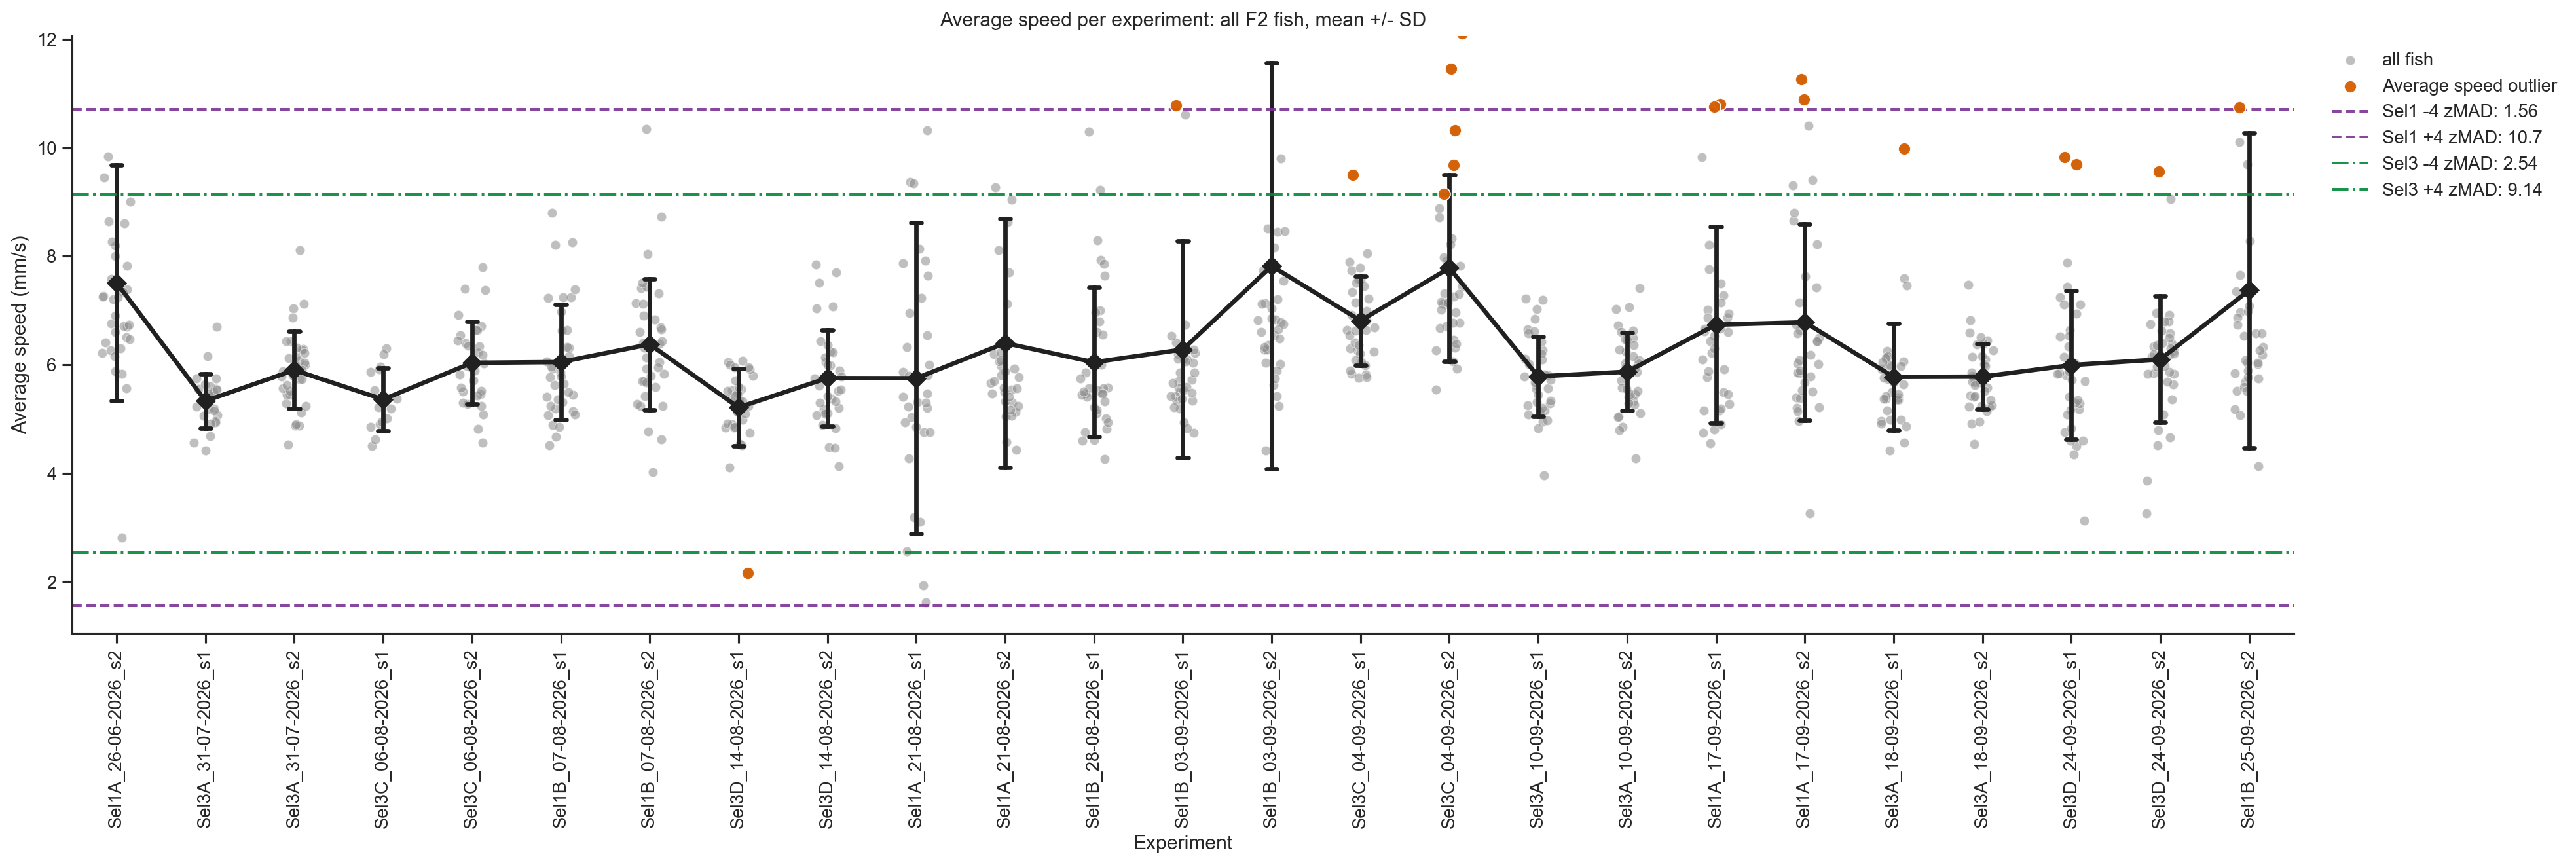

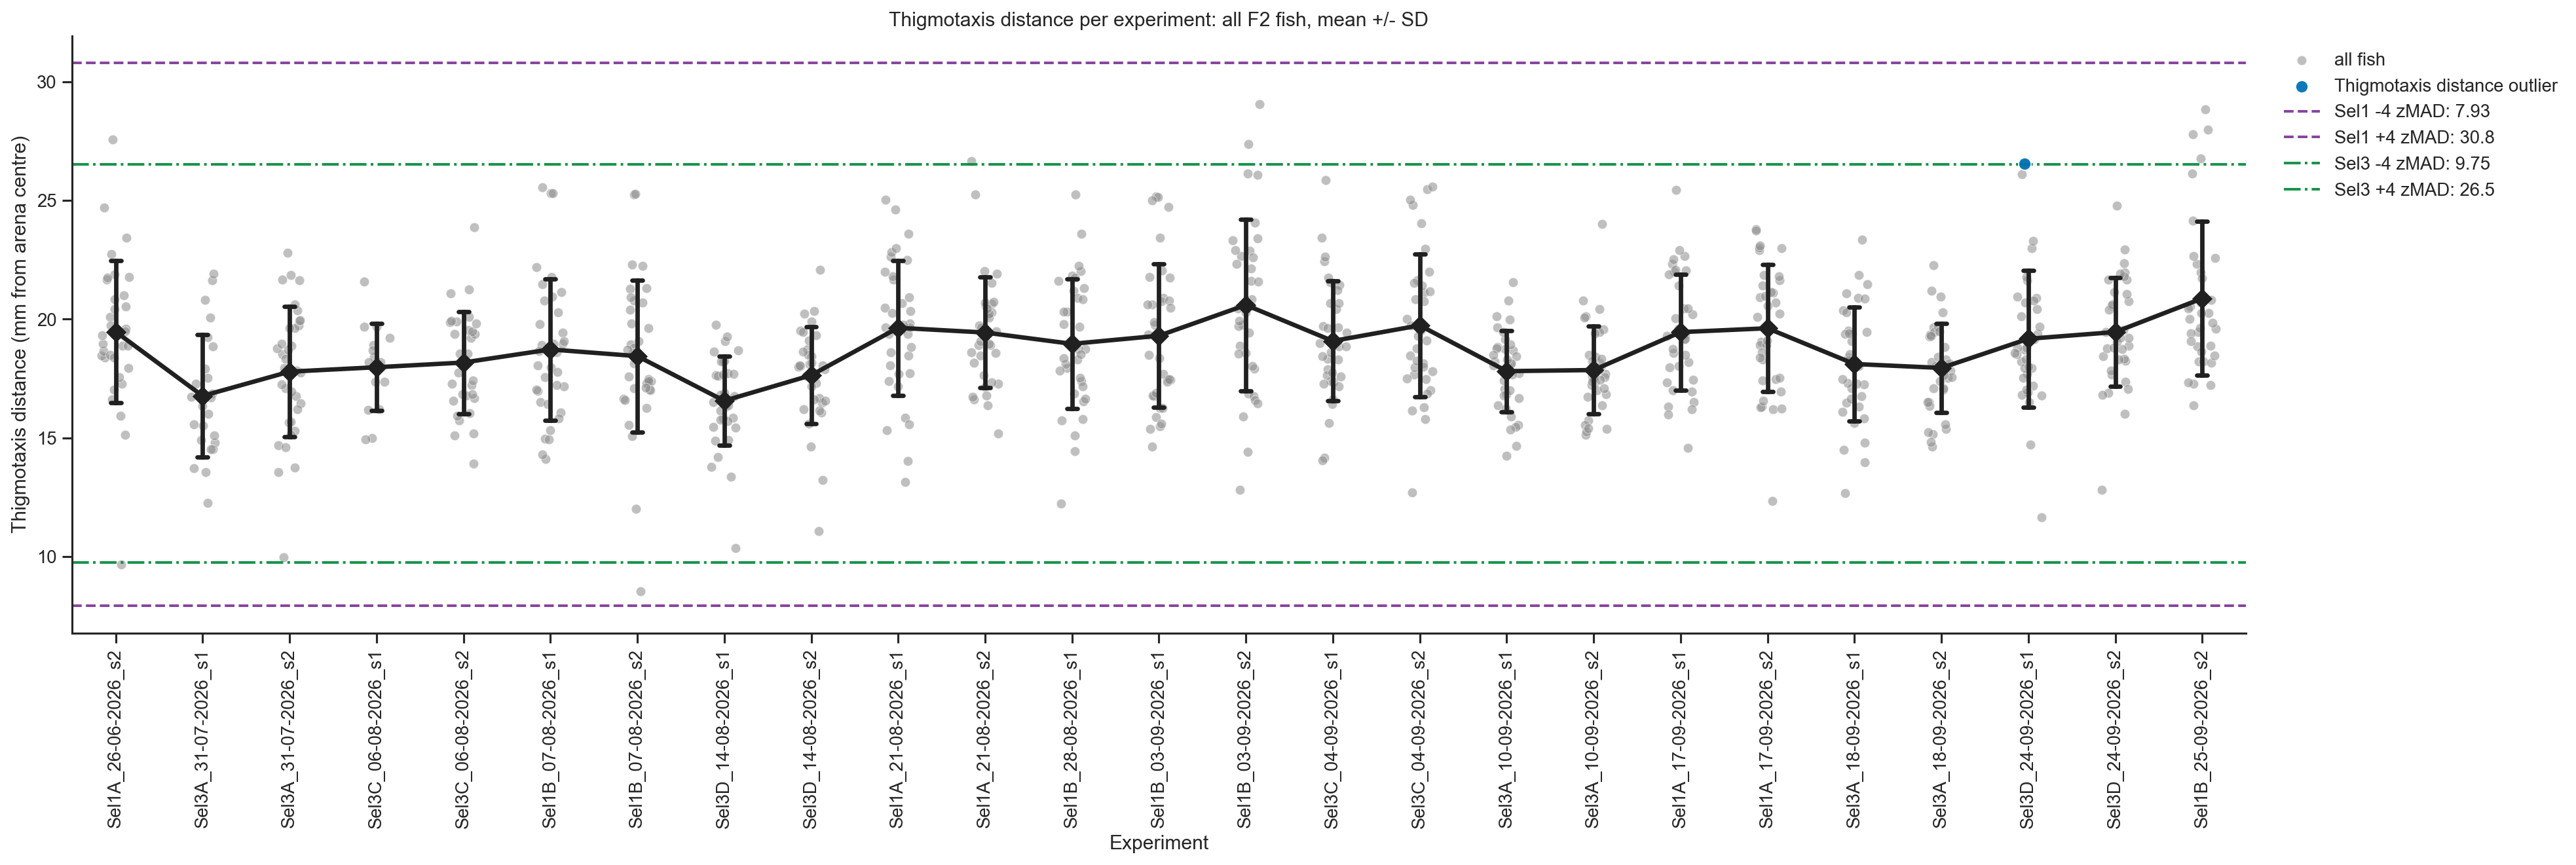

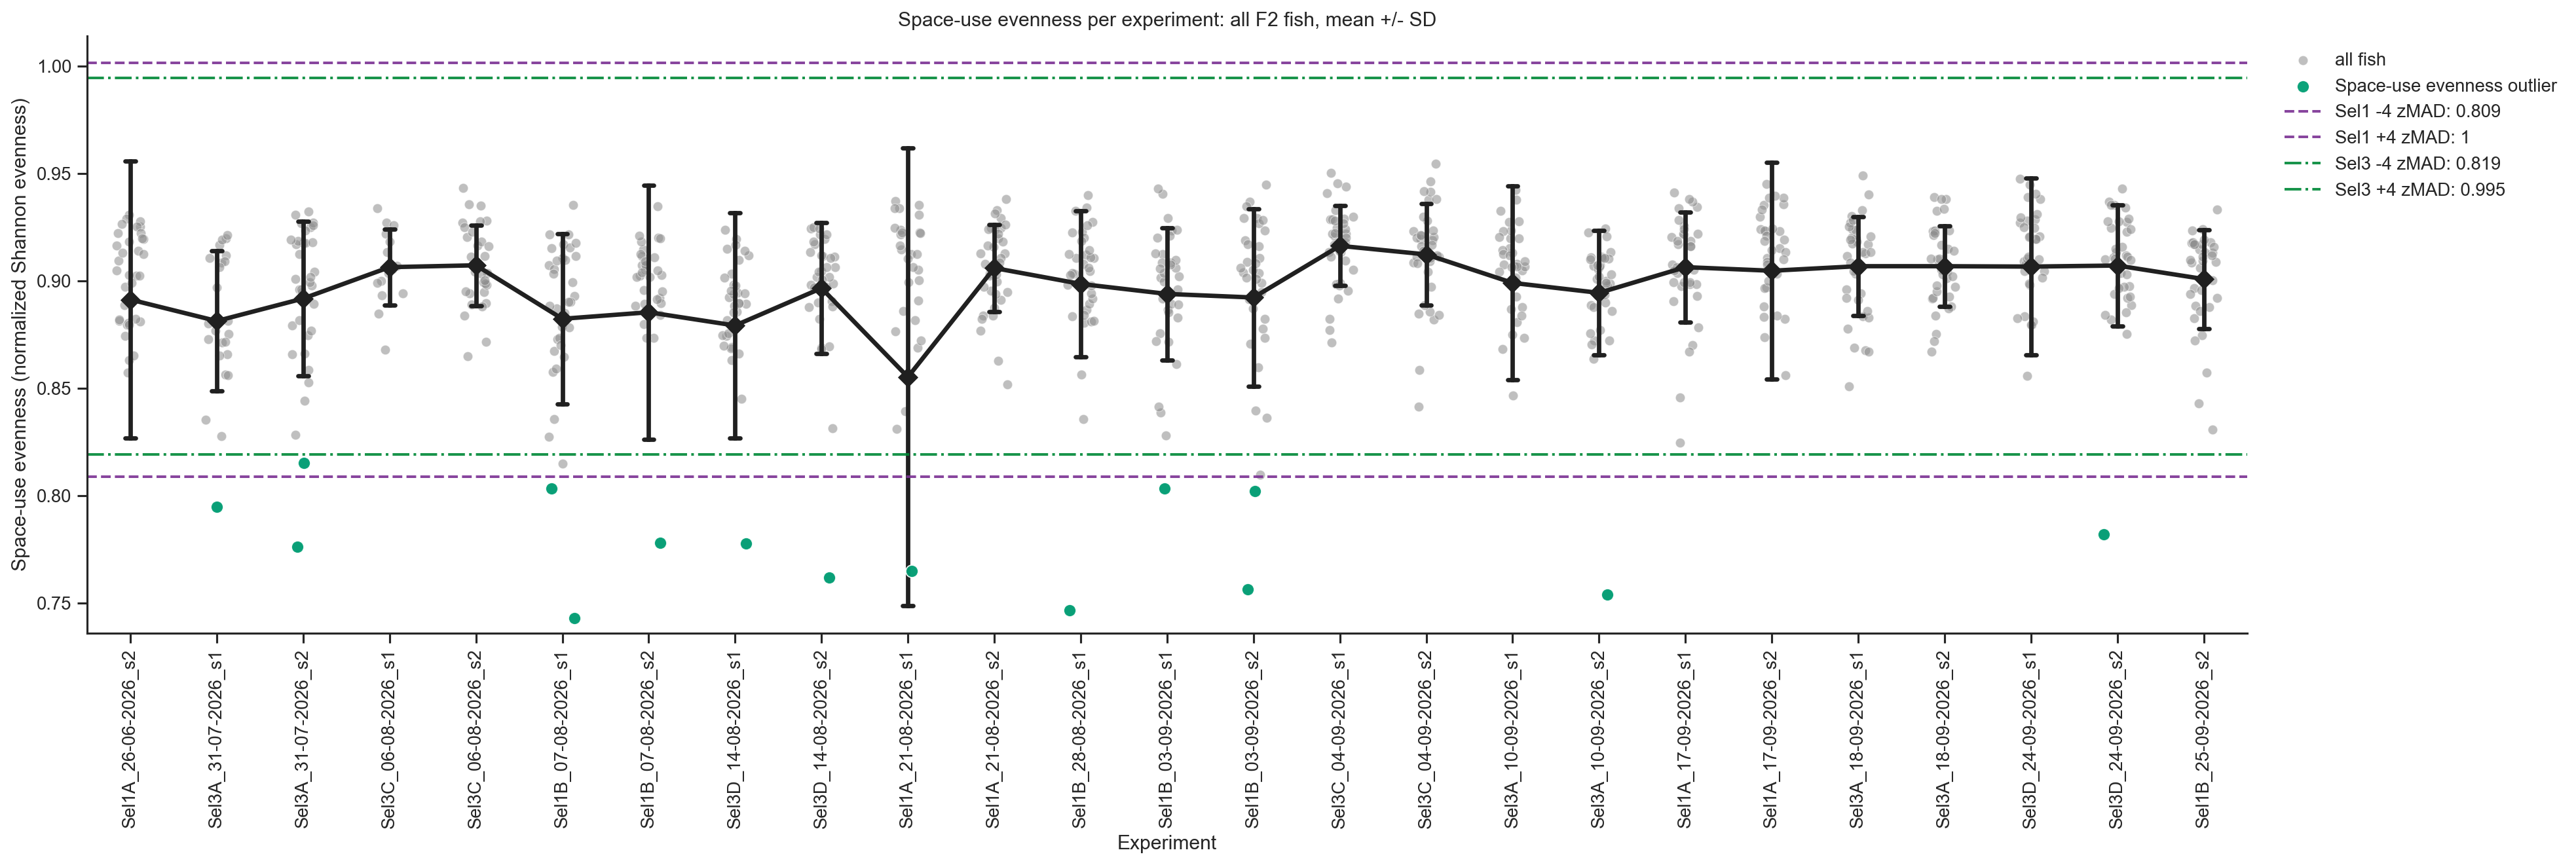

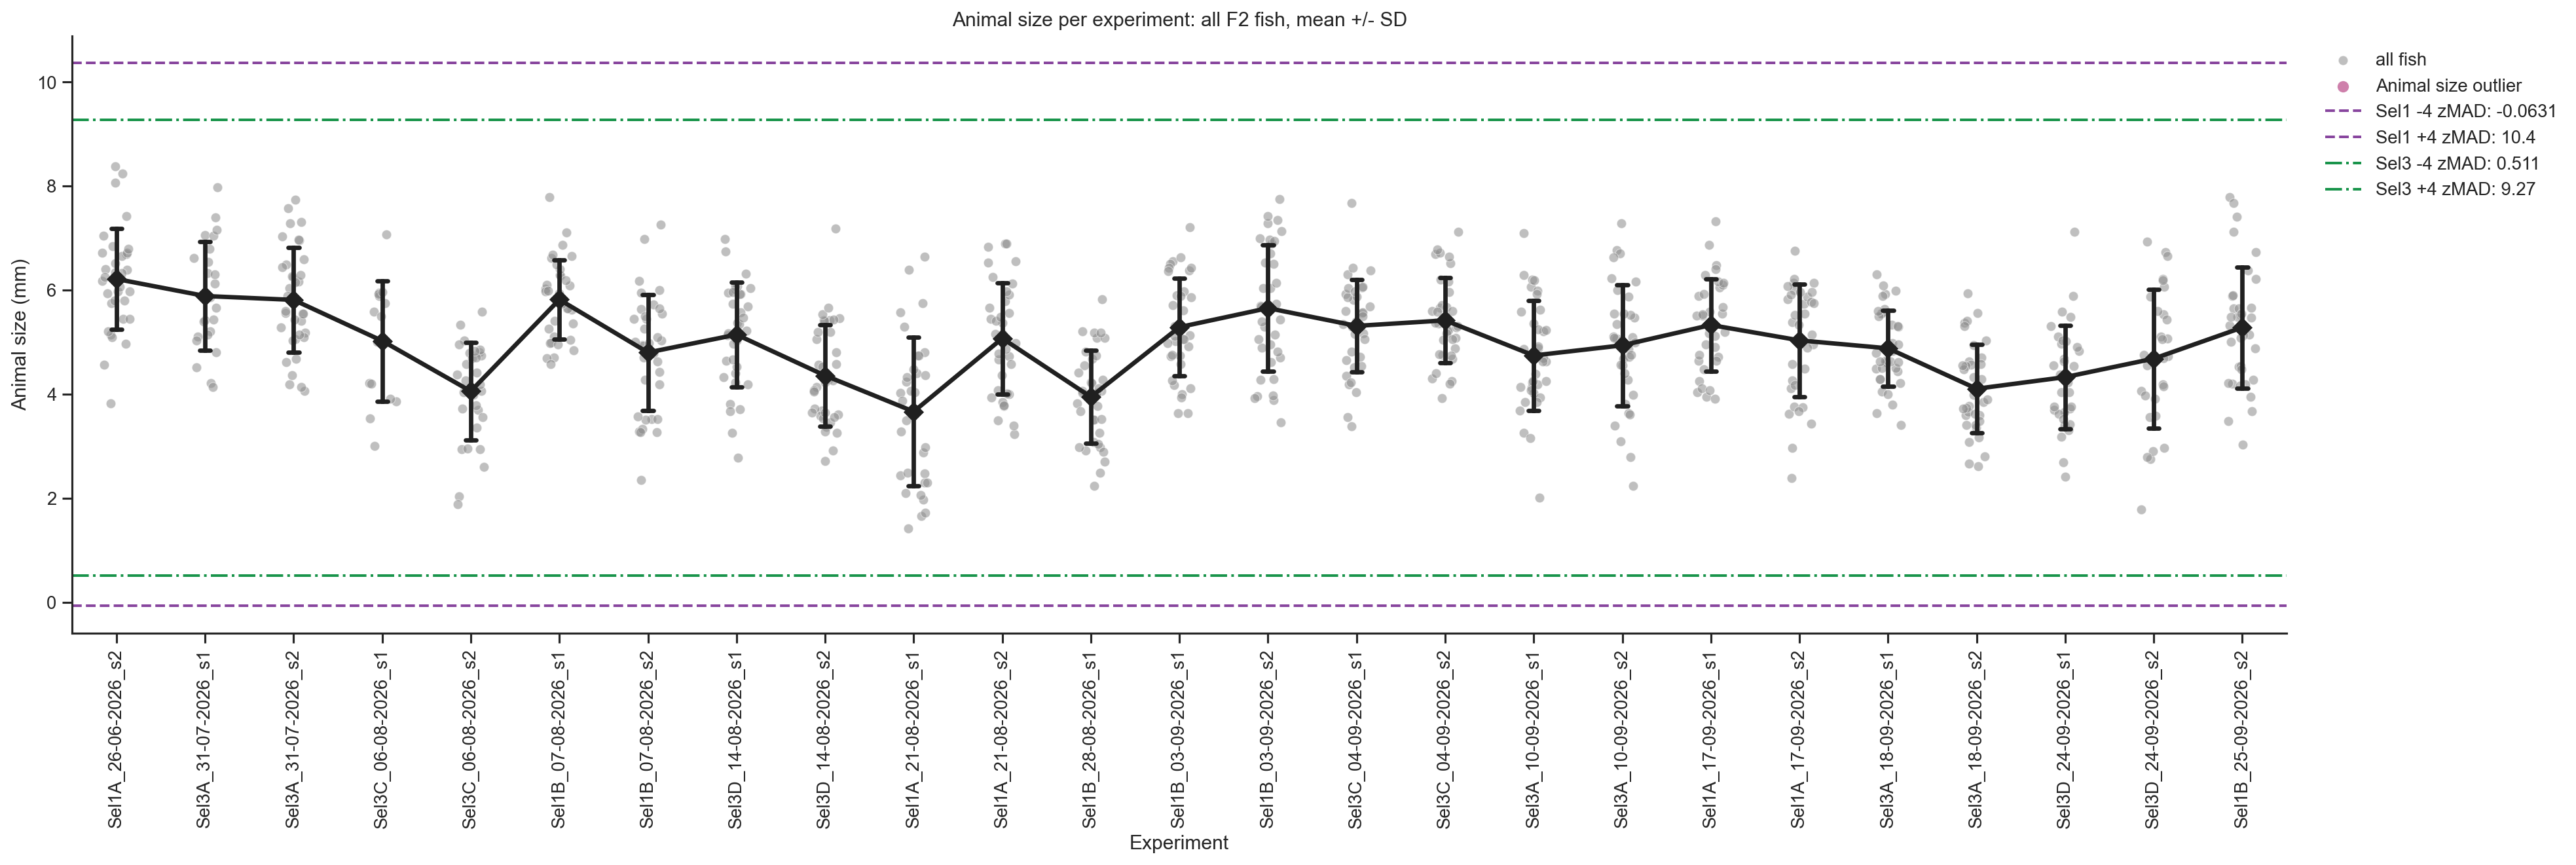

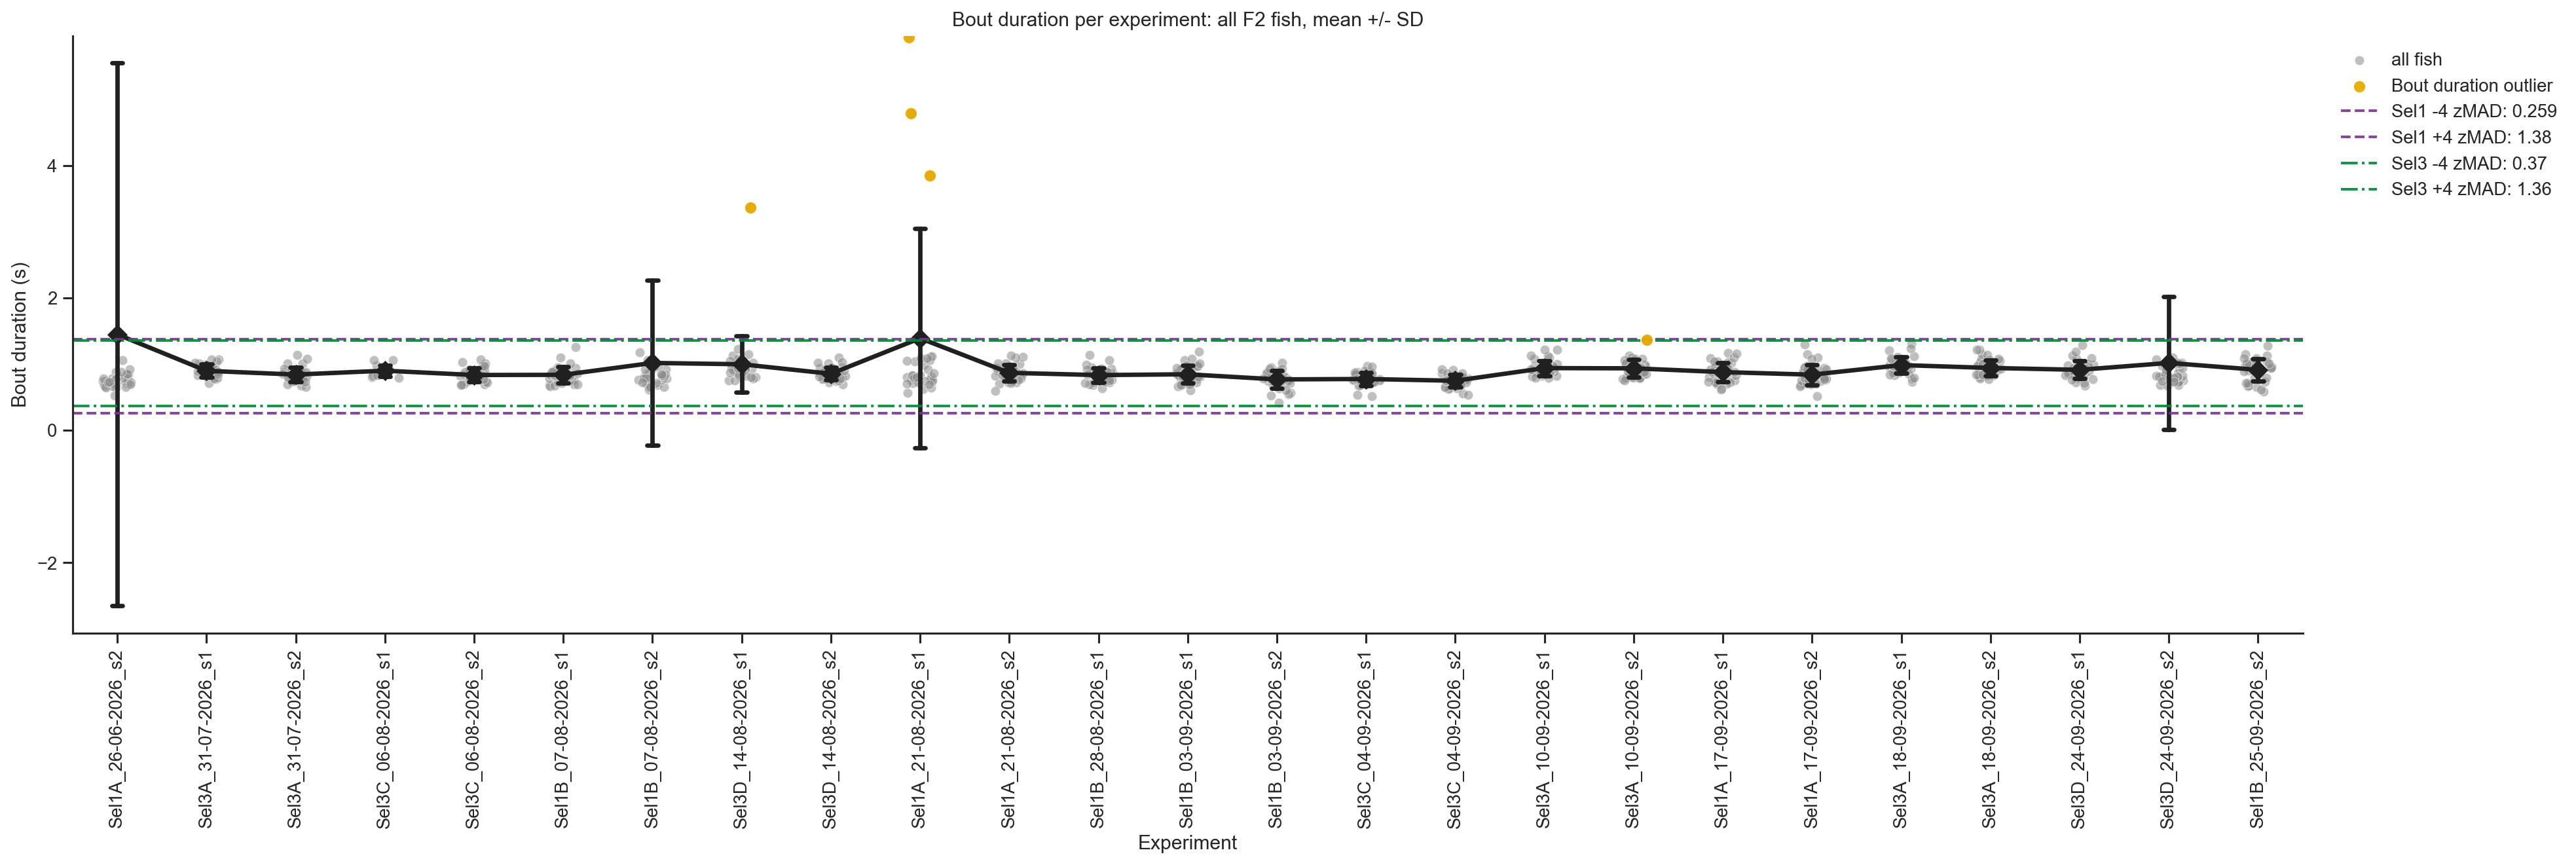

In [10]:
def experiment_plot_order(data):
    """Order experiment labels chronologically, retaining a stable secondary label sort."""
    return (
        data[['experiment_label', 'date']]
        .drop_duplicates()
        .sort_values(['date', 'experiment_label'])['experiment_label']
        .tolist()
    )


def stable_jitter_position(experiment_label, qtlid, experiment_order, width=0.16):
    """Create repeatable horizontal jitter from the experiment-animal identifier."""
    x_centre = experiment_order.index(experiment_label)
    token = f'{experiment_label}|{qtlid}'.encode('utf-8')
    integer = int(hashlib.sha1(token).hexdigest()[:8], 16)
    unit_value = integer / float(16 ** 8 - 1)
    return x_centre + (unit_value - 0.5) * 2 * width


def add_stable_plot_positions(data, experiment_order):
    """Attach deterministic x positions for QC annotation overlays."""
    positioned = data.copy()
    positioned['_plot_x'] = [
        stable_jitter_position(label, qtlid, experiment_order)
        for label, qtlid in zip(positioned['experiment_label'], positioned['QTLID'])
    ]
    return positioned


def save_figure(fig, stem):
    """Save both review-friendly PNG and vector PDF versions when enabled."""
    if not SAVE_OUTPUTS:
        return
    fig.savefig(Path(OUTPUT_DIR) / f'{stem}.png', dpi=FIGURE_DPI, bbox_inches='tight')
    fig.savefig(Path(OUTPUT_DIR) / f'{stem}.pdf', bbox_inches='tight')


def pointplot_y_limits(metric_name):
    """Validate one optional user-editable y-axis override."""
    unknown_metrics = set(QC_POINTPLOT_Y_LIMITS) - set(QC_METRICS)
    if unknown_metrics:
        raise KeyError(
            'QC_POINTPLOT_Y_LIMITS contains unknown metric key(s): '
            + ', '.join(sorted(unknown_metrics))
        )

    limits = QC_POINTPLOT_Y_LIMITS.get(metric_name)
    if limits is None:
        return None
    if (
        not isinstance(limits, (tuple, list))
        or len(limits) != 2
        or not all(np.isfinite(limits))
    ):
        raise ValueError(
            f'QC_POINTPLOT_Y_LIMITS[{metric_name!r}] must be None or '
            'a two-value finite (lower, upper) tuple.'
        )
    lower_limit, upper_limit = map(float, limits)
    if upper_limit <= lower_limit:
        raise ValueError(
            f'QC_POINTPLOT_Y_LIMITS[{metric_name!r}] must satisfy lower < upper.'
        )
    return lower_limit, upper_limit


def plot_metric_by_experiment(data, reference_table, metric_name):
    """Plot non-missing metric values, mean/SD, and active-reference cutoffs."""
    metric_info = QC_METRICS[metric_name]
    value_column = metric_info['column']
    outlier_column = f'{metric_name}_outlier_flag'
    order = experiment_plot_order(data)
    positioned = add_stable_plot_positions(data, order)
    finite = positioned[positioned[value_column].notna()].copy()

    fig_width = max(9, 0.8 * len(order) + 2)
    fig, ax = plt.subplots(
        figsize=(fig_width, QC_POINTPLOT_HEIGHT),
        dpi=FIGURE_DPI,
    )

    # Draw each sample with an available metric value before highlighting outliers.
    ax.scatter(
        finite['_plot_x'],
        finite[value_column],
        s=34,
        color=UNFLAGGED_COLOR,
        alpha=0.55,
        edgecolor='white',
        linewidth=0.4,
        zorder=2,
        label='all fish',
    )
    metric_outliers = finite[finite[outlier_column]]
    ax.scatter(
        metric_outliers['_plot_x'],
        metric_outliers[value_column],
        s=58,
        color=metric_info['color'],
        edgecolor='white',
        linewidth=0.7,
        alpha=0.95,
        zorder=4,
        label=f'{metric_info["label"]} outlier',
    )

    # The pointplot includes all non-missing metric values, including outliers.
    sns.pointplot(
        data=finite,
        x='experiment_label',
        y=value_column,
        order=order,
        color=SUMMARY_COLOR,
        errorbar='sd',
        linestyle='-',
        markers='D',
        capsize=0.12,
        ax=ax,
    )

    threshold_styles = {
        'Global pooled': {'color': metric_info['color'], 'linestyle': ':'},
        'Sel1': {'color': '#7B3294', 'linestyle': '--'},
        'Sel3': {'color': '#008837', 'linestyle': '-.'},
    }
    metric_references = reference_table.loc[reference_table['metric'].eq(metric_name)]
    for _, reference in metric_references.iterrows():
        group_name = reference['threshold_group']
        style = threshold_styles[group_name]
        for threshold_value, threshold_label in (
            (reference['lower_threshold'], f'-{reference["zmad_threshold"]:g} zMAD'),
            (reference['upper_threshold'], f'+{reference["zmad_threshold"]:g} zMAD'),
        ):
            if np.isfinite(threshold_value):
                ax.axhline(
                    threshold_value,
                    linewidth=1.6,
                    alpha=0.9,
                    label=(
                        f'{group_name} {threshold_label}: {threshold_value:.3g}'
                    ),
                    **style,
                )

    # Apply a user-requested range after every artist is drawn, so the chosen
    # limits govern points, SD bars, and active threshold lines together.
    y_limits = pointplot_y_limits(metric_name)
    if y_limits is not None:
        ax.set_ylim(*y_limits)
        below = np.isfinite(finite[value_column]) & finite[value_column].lt(y_limits[0])
        above = np.isfinite(finite[value_column]) & finite[value_column].gt(y_limits[1])
        below_review = int((below & finite['qc_review_flag']).sum())
        above_review = int((above & finite['qc_review_flag']).sum())
        ax.text(
            0.02, 0.98,
            f'Hidden below: {int(below.sum())} points ({below_review} review flagged)\n'
            f'Hidden above: {int(above.sum())} points ({above_review} review flagged)',
            transform=ax.transAxes, ha='left', va='top', fontsize=8,
            bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none'},
        )

    ax.set_xlabel('Experiment')
    ax.set_ylabel(f'{metric_info["label"]} ({metric_info["unit"]})')
    ax.set_title(
        f'{metric_info["label"]} per experiment: all F2 fish, mean +/- SD'
    )
    ax.tick_params(axis='x', rotation=90)
    ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
    sns.despine(ax=ax)
    fig.tight_layout()
    return fig, ax


metric_figures = {}
for metric_name in QC_METRICS:
    metric_figures[metric_name] = plot_metric_by_experiment(
        qc_table,
        qc_reference,
        metric_name,
    )
    save_figure(
        metric_figures[metric_name][0],
        f'qtl_qc_{metric_name}_by_experiment',
    )

plt.show()

### Additional QC plots ordered by line and date

These figures show only Sel1 and Sel3 samples in separate panels with a shared y-axis. Within each family, experiments are ordered case-insensitively by line, then date and label.

Points and summaries use selection-line colors; metric-specific outliers have hollow rings in the metric color. Each experiment is summarized by its median +/- normal-scaled MAD (`1.4826 * MAD`), including outliers with available values.

Only matching-family cutoff lines are shown. Global threshold mode produces no cutoff lines in these panels. Undefined family cutoffs are also omitted.

Axis ranges are automatic by default. Optional manual limits display hidden finite-point counts separately for each family, including samples requiring QC review.


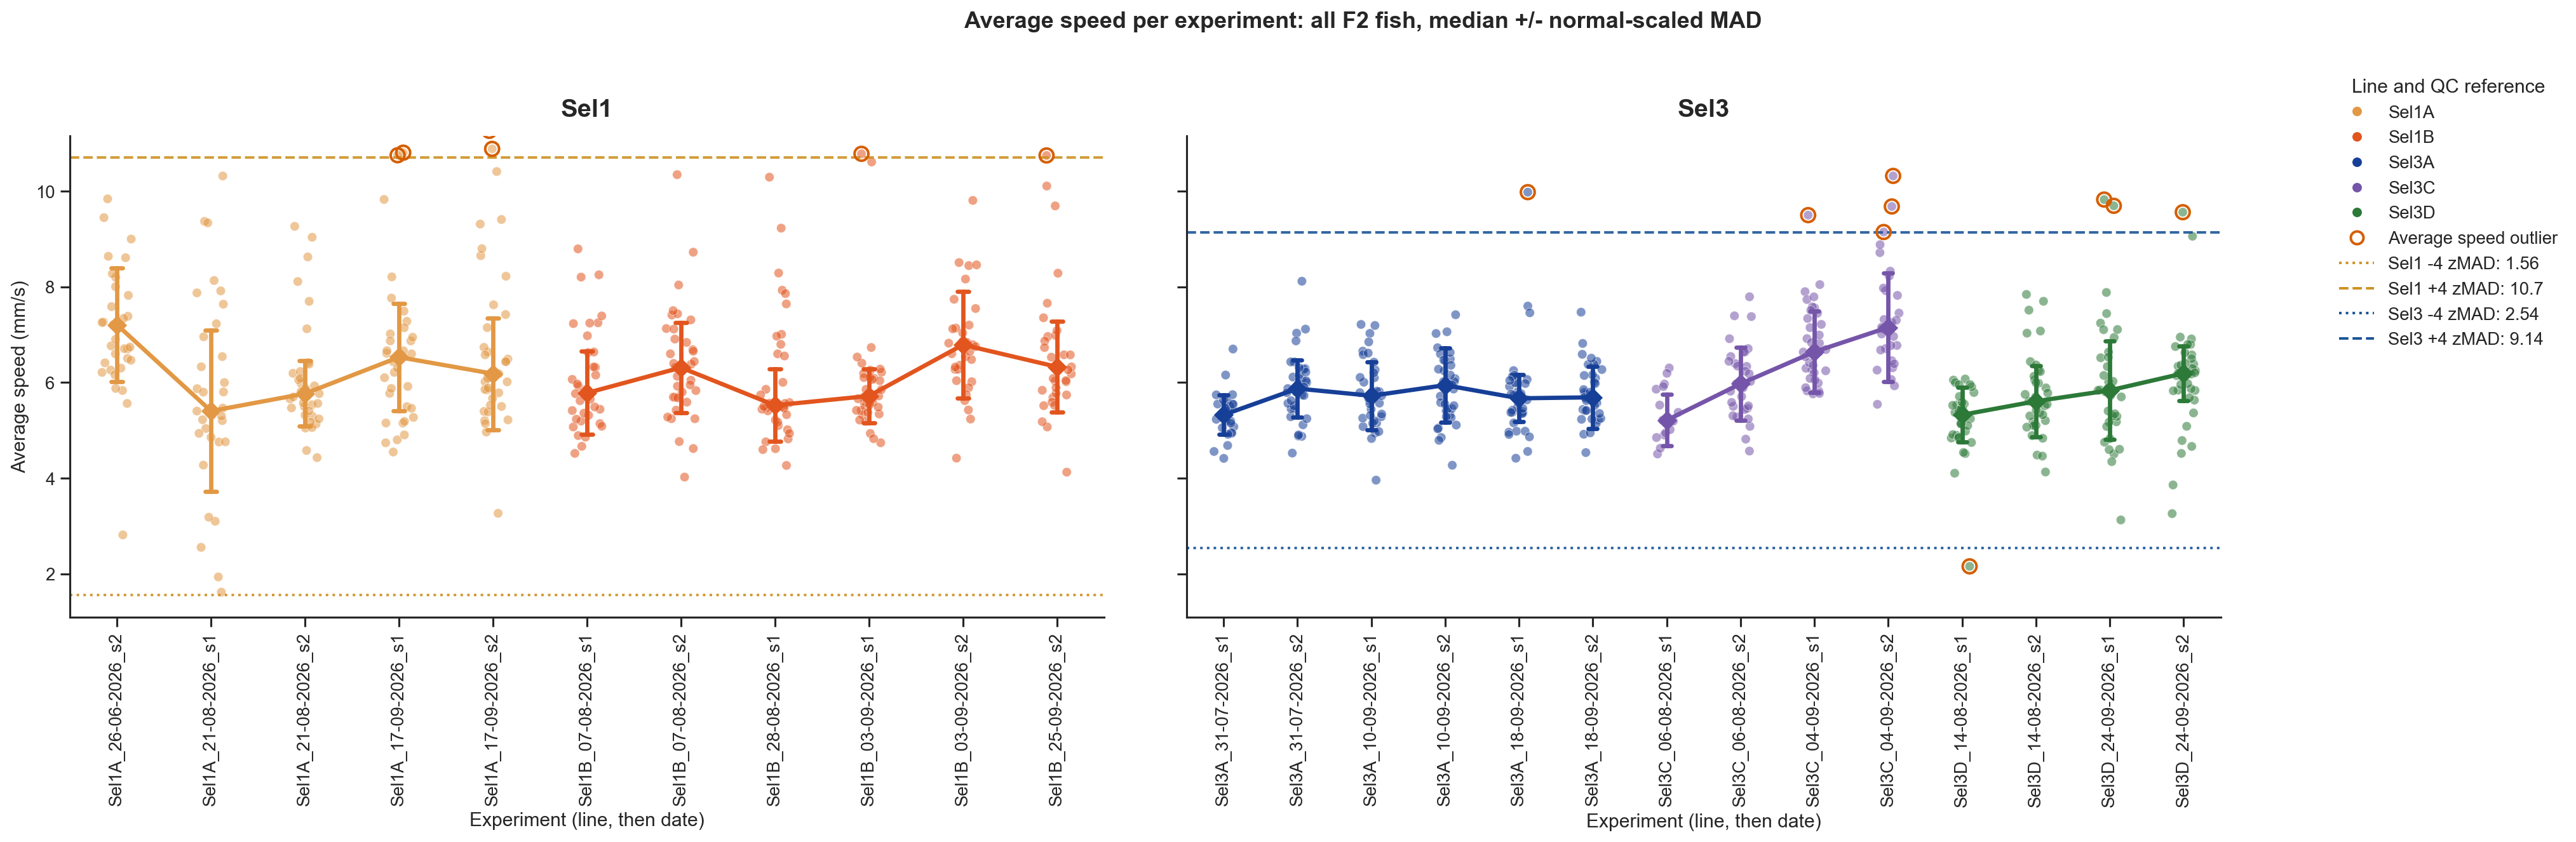

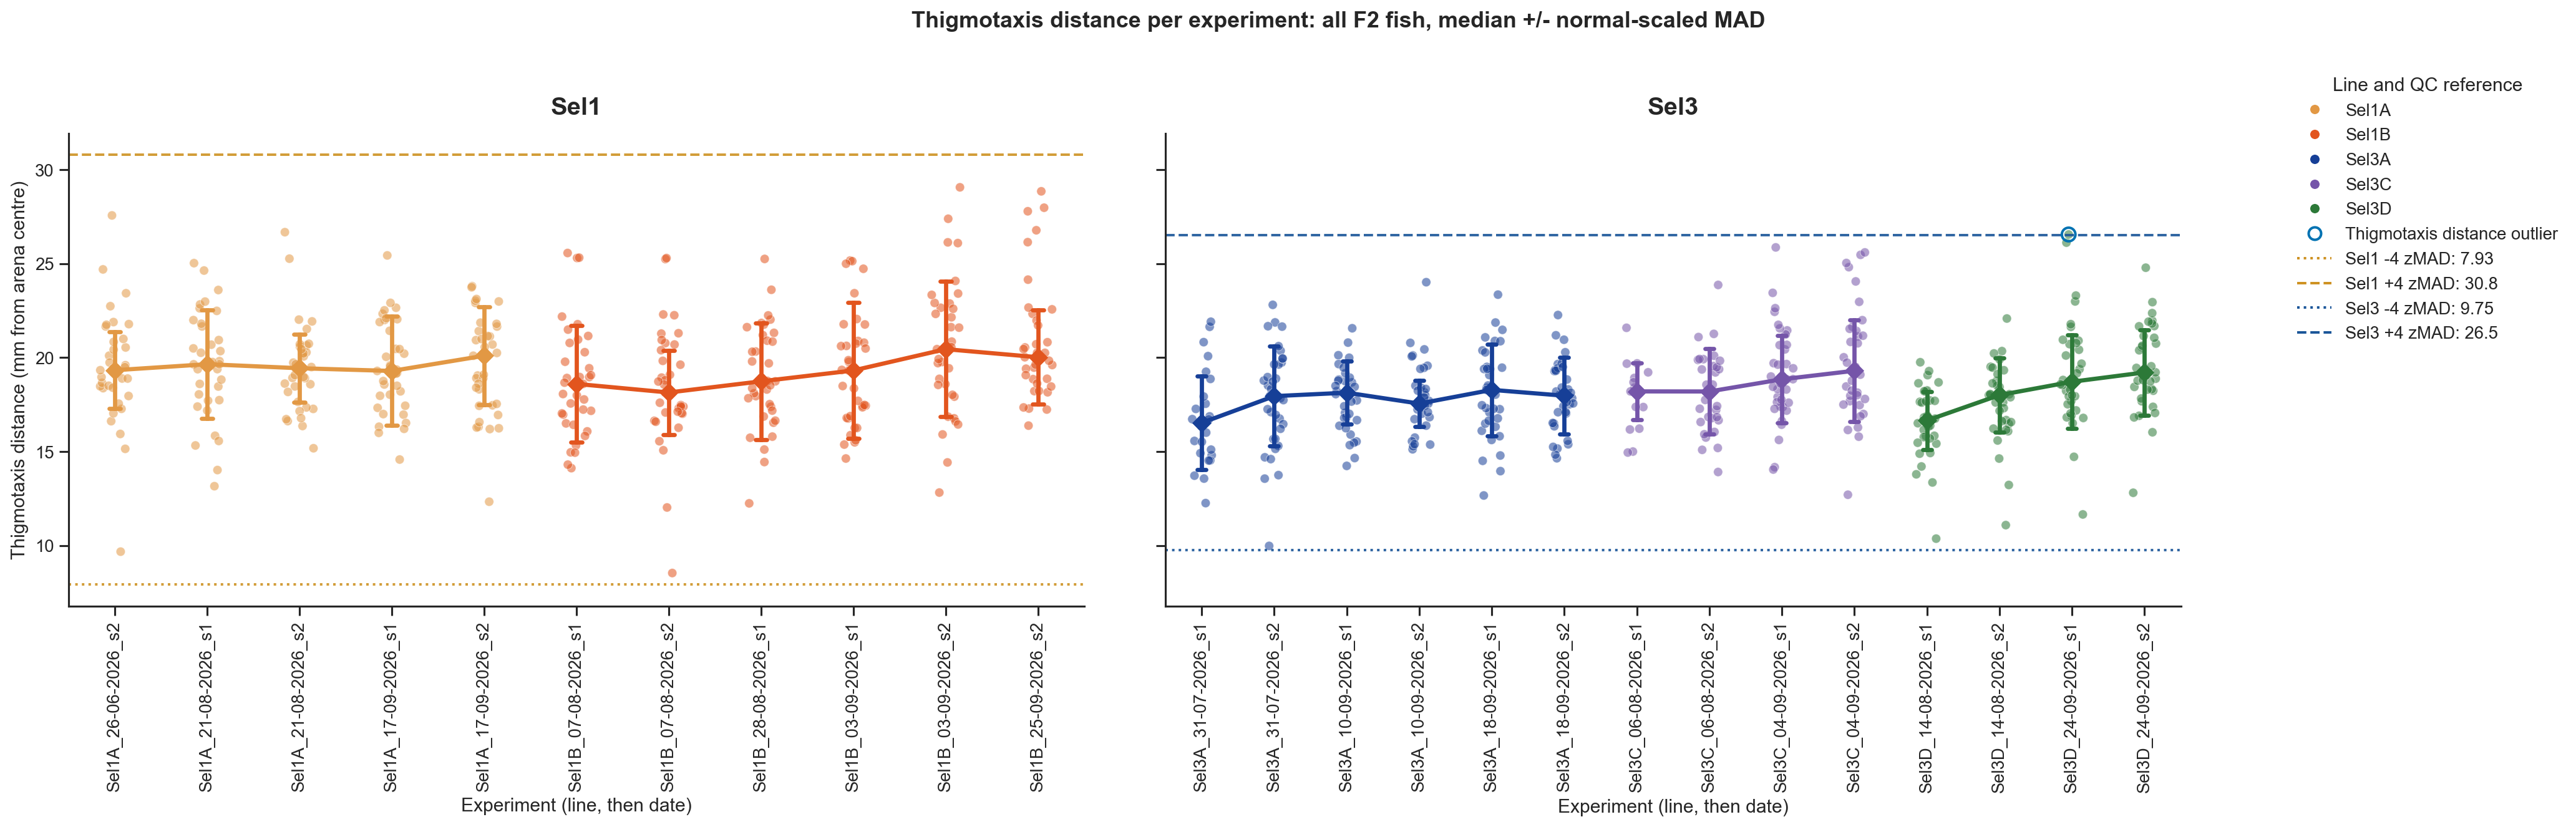

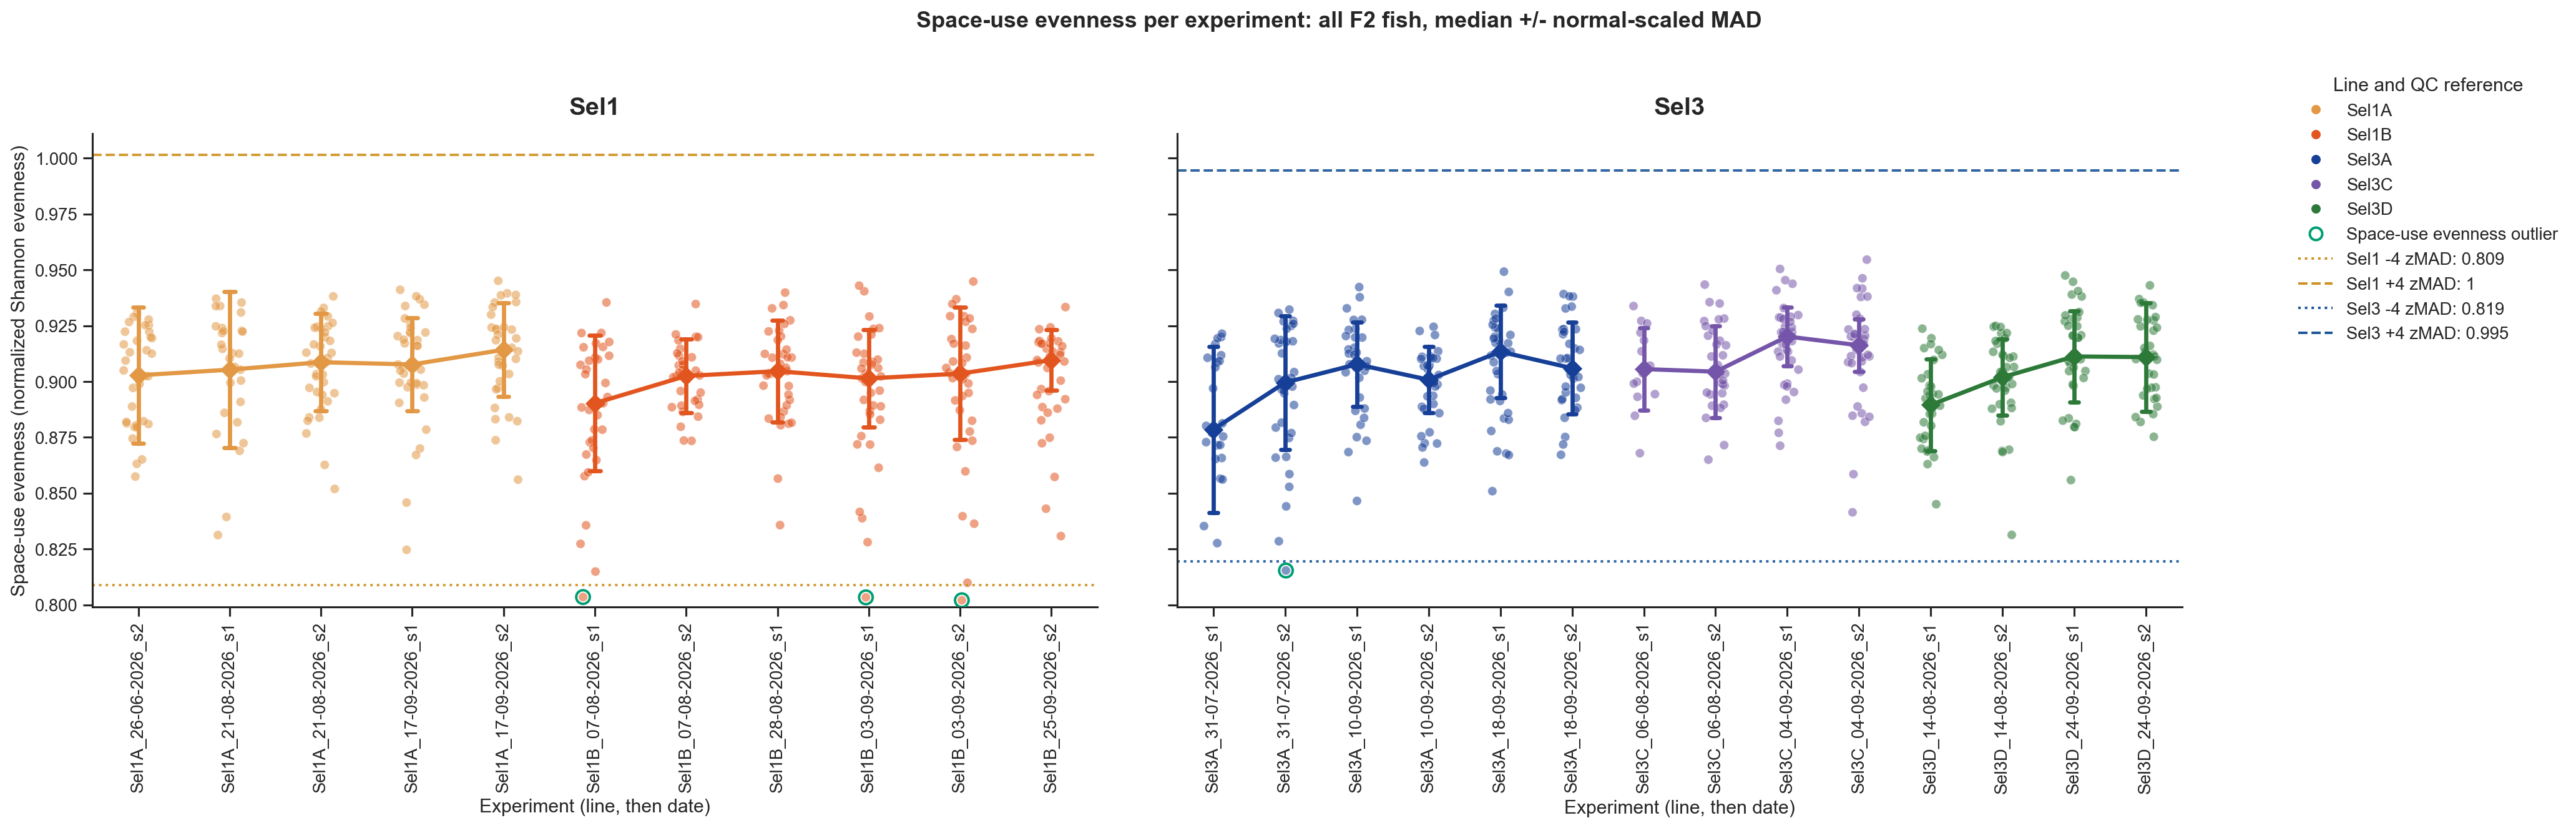

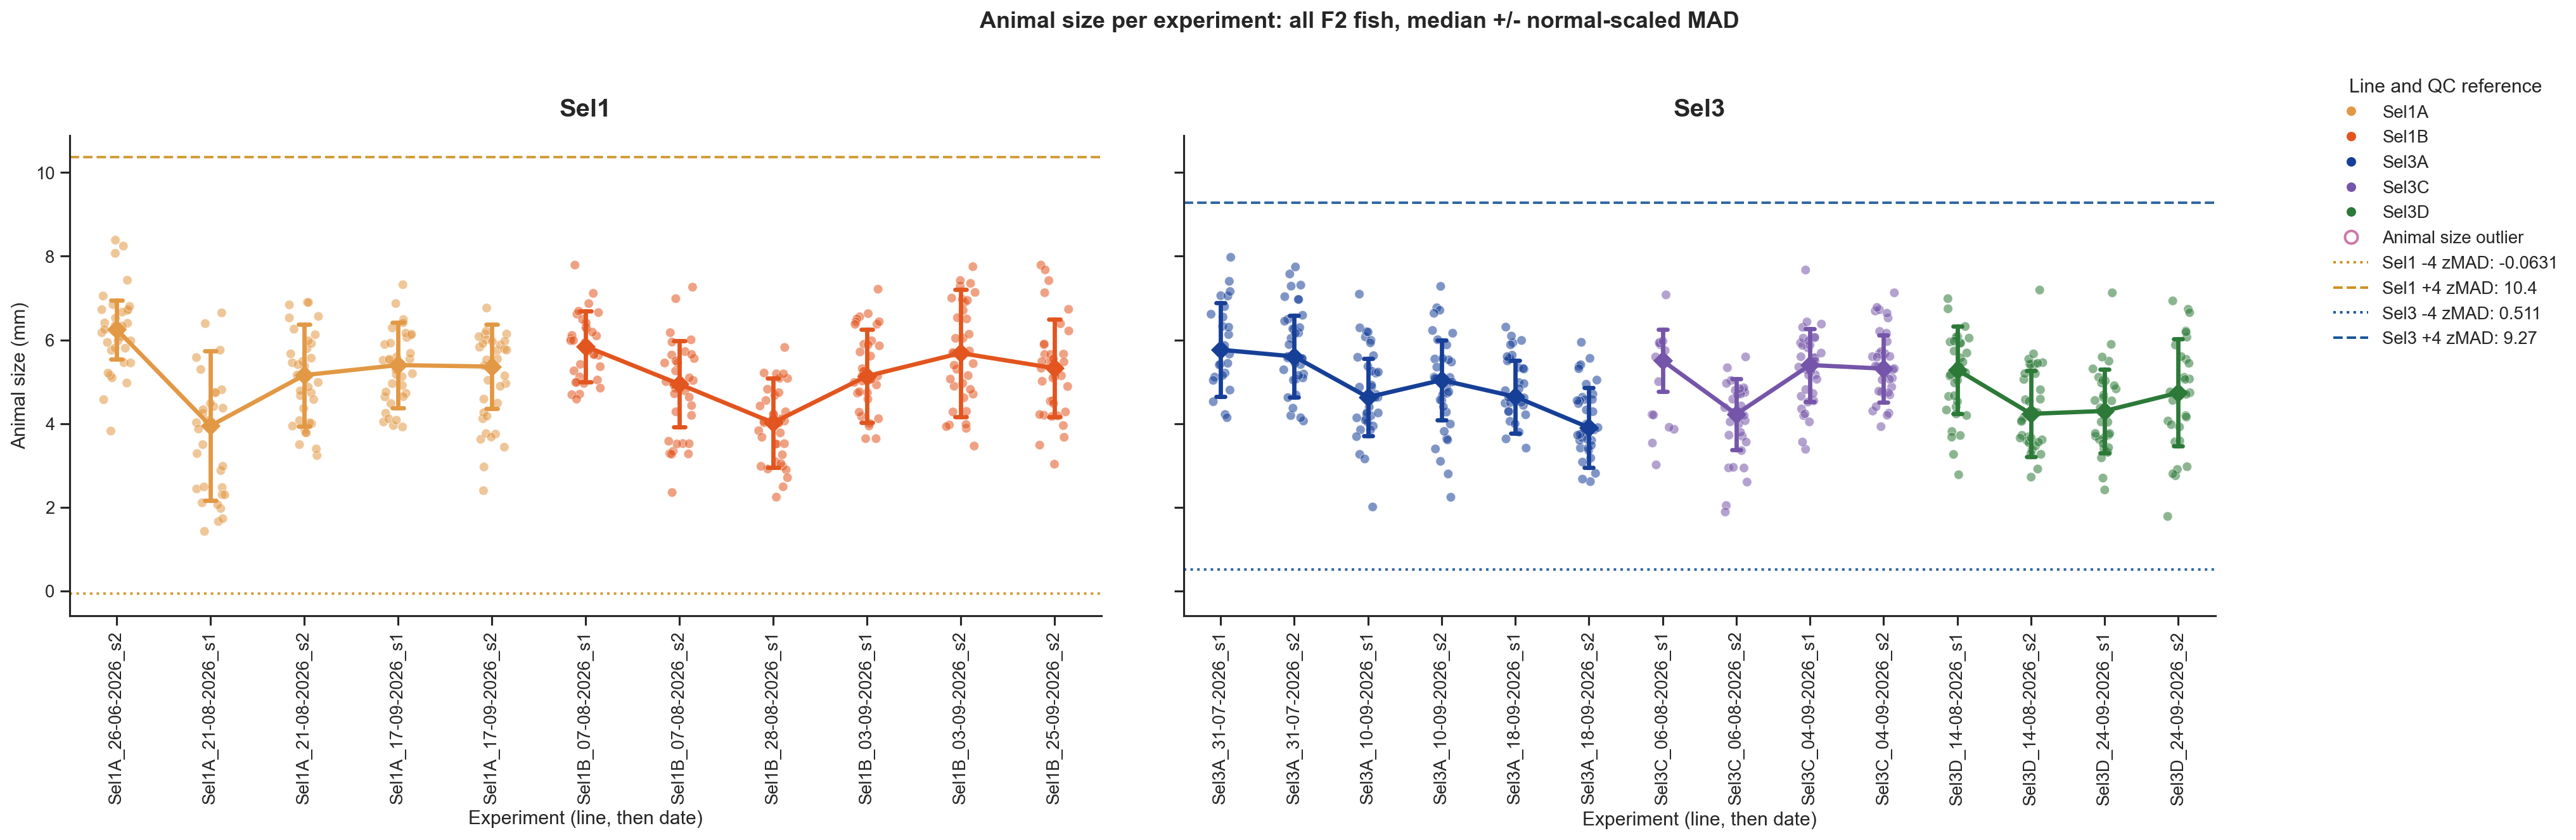

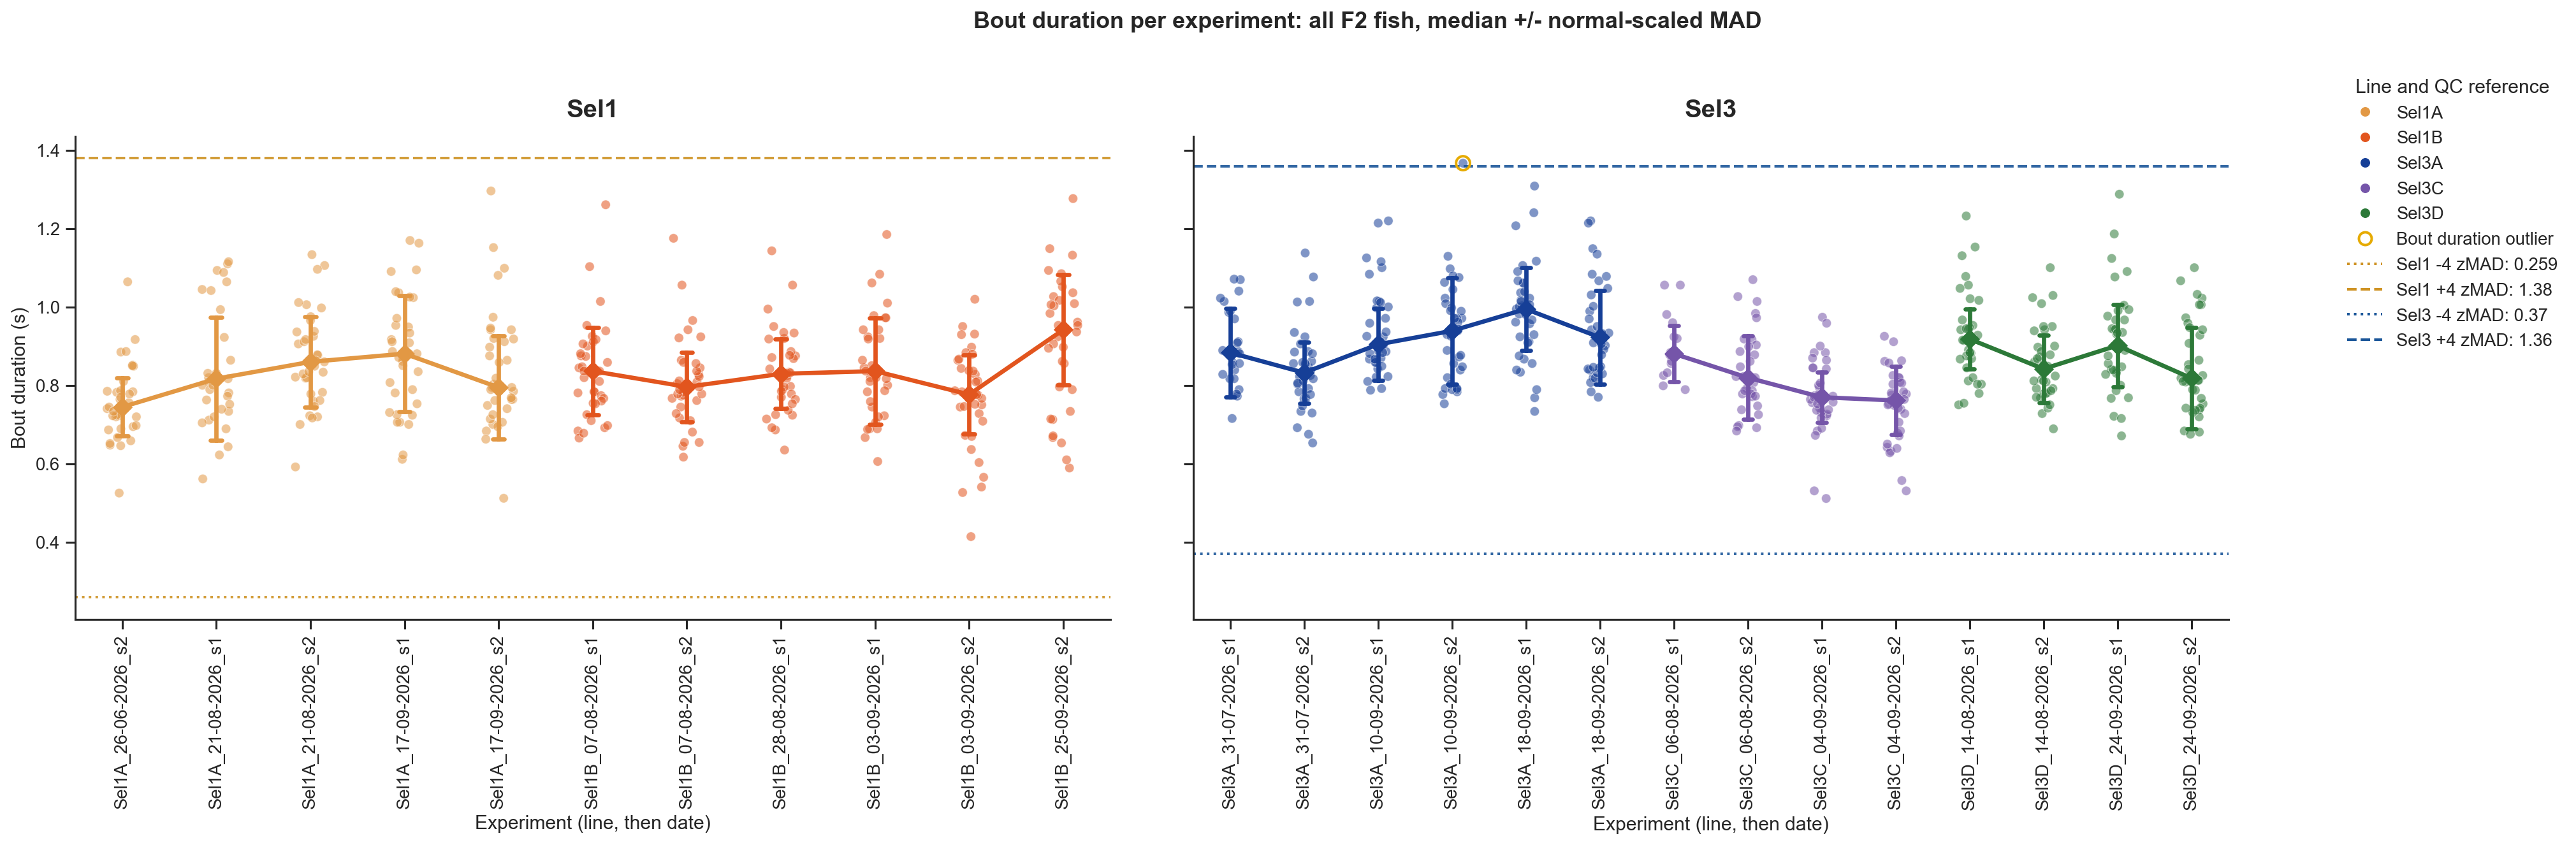

In [11]:
def experiment_plot_order_by_line_and_date(data):
    """Order experiments case-insensitively by line, then date and label."""
    return (
        data[['experiment_label', 'line', 'date']]
        .drop_duplicates()
        .assign(_line_order=lambda frame: frame['line'].str.casefold())
        .sort_values(['_line_order', 'date', 'experiment_label'])
        ['experiment_label']
        .tolist()
    )


def median_mad_interval(values):
    """Return median +/- normal-scaled MAD after dropping missing numeric values."""
    numeric = pd.to_numeric(pd.Series(values), errors='coerce').dropna()
    median = numeric.median()
    mad = (numeric - median).abs().median()
    scaled_mad = 1.4826 * mad
    return median - scaled_mad, median + scaled_mad


qc_line_palette = {
    'Sel1A': '#E29844',
    'Sel1B': '#E2551E',
    'Sel3A': '#163F97',
    'Sel3C': '#7555A9',
    'Sel3D': '#2C7938',
}
qc_family_palette = {
    'Sel1': '#CE9223',
    'Sel3': '#1B5699',
}
qc_panel_families = ['Sel1', 'Sel3']


def plot_metric_by_line_and_date(data, reference_table, metric_name):
    """Plot one QC metric in line/date-ordered Sel1 and Sel3 panels."""
    metric_info = QC_METRICS[metric_name]
    value_column = metric_info['column']
    outlier_column = f'{metric_name}_outlier_flag'

    panel_data = data.copy()
    panel_data['selection_family'] = panel_data['line'].map(
        selection_family_for_threshold
    )
    panel_data = panel_data.loc[
        panel_data['selection_family'].isin(qc_panel_families)
    ].copy()
    if panel_data.empty:
        raise ValueError('No Sel1 or Sel3 samples are available for the QC panels.')

    missing_line_colors = (
        set(panel_data['line'].dropna().unique()) - set(qc_line_palette)
    )
    if missing_line_colors:
        raise ValueError(
            'Missing QC panel colors for lines: '
            + ', '.join(sorted(missing_line_colors))
        )

    experiment_count = panel_data['experiment_label'].nunique()
    fig_width = max(13, 0.8 * experiment_count + 4)
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(fig_width, QC_POINTPLOT_HEIGHT),
        dpi=FIGURE_DPI,
        sharey='row',
    )
    plotted_lines = []
    threshold_handles = []

    for ax, family in zip(axes, qc_panel_families):
        family_data = panel_data.loc[
            panel_data['selection_family'].eq(family)
        ].copy()
        if family_data.empty:
            raise ValueError(f'No {family} samples are available for the QC panels.')

        order = experiment_plot_order_by_line_and_date(family_data)
        positioned = add_stable_plot_positions(family_data, order)
        finite = positioned[positioned[value_column].notna()].copy()
        family_lines = (
            family_data[['line']]
            .drop_duplicates()
            .assign(_line_order=lambda frame: frame['line'].str.casefold())
            .sort_values('_line_order')['line']
            .tolist()
        )
        plotted_lines.extend(family_lines)

        ax.scatter(
            finite['_plot_x'],
            finite[value_column],
            s=34,
            c=finite['line'].map(qc_line_palette),
            alpha=0.55,
            edgecolor='white',
            linewidth=0.4,
            zorder=2,
        )
        metric_outliers = finite[finite[outlier_column]]
        ax.scatter(
            metric_outliers['_plot_x'],
            metric_outliers[value_column],
            s=76,
            facecolors='none',
            edgecolors=metric_info['color'],
            linewidth=1.6,
            zorder=4,
        )

        sns.pointplot(
            data=finite,
            x='experiment_label',
            y=value_column,
            hue='line',
            hue_order=family_lines,
            palette=qc_line_palette,
            order=order,
            dodge=False,
            estimator=np.median,
            errorbar=median_mad_interval,
            linestyle='-',
            markers='D',
            capsize=0.12,
            legend=False,
            ax=ax,
        )

        family_references = reference_table.loc[
            reference_table['metric'].eq(metric_name)
            & reference_table['threshold_group'].eq(family)
        ]
        for _, reference in family_references.iterrows():
            for threshold_value, threshold_label, linestyle in (
                (
                    reference['lower_threshold'],
                    f'-{reference["zmad_threshold"]:g} zMAD',
                    ':',
                ),
                (
                    reference['upper_threshold'],
                    f'+{reference["zmad_threshold"]:g} zMAD',
                    '--',
                ),
            ):
                if np.isfinite(threshold_value):
                    ax.axhline(
                        threshold_value,
                        color=qc_family_palette[family],
                        linestyle=linestyle,
                        linewidth=1.6,
                        alpha=0.9,
                    )
                    threshold_handles.append(
                        Line2D(
                            [0],
                            [0],
                            color=qc_family_palette[family],
                            linestyle=linestyle,
                            linewidth=1.6,
                            label=(
                                f'{family} {threshold_label}: '
                                f'{threshold_value:.3g}'
                            ),
                        )
                    )

        ax.set_xlabel('Experiment (line, then date)')
        ax.set_title(family, fontsize=16, fontweight='bold', pad=12)
        ax.tick_params(axis='x', rotation=90)
        sns.despine(ax=ax)

    y_limits = pointplot_y_limits(metric_name)
    if y_limits is not None:
        for ax, family in zip(axes, qc_panel_families):
            ax.set_ylim(*y_limits)
            finite = panel_data.loc[
                panel_data['selection_family'].eq(family)
                & panel_data[value_column].notna()
            ]
            below = np.isfinite(finite[value_column]) & finite[value_column].lt(y_limits[0])
            above = np.isfinite(finite[value_column]) & finite[value_column].gt(y_limits[1])
            below_review = int((below & finite['qc_review_flag']).sum())
            above_review = int((above & finite['qc_review_flag']).sum())
            ax.text(
                0.02, 0.98,
                f'Hidden below: {int(below.sum())} points ({below_review} review flagged)\n'
                f'Hidden above: {int(above.sum())} points ({above_review} review flagged)',
                transform=ax.transAxes, ha='left', va='top', fontsize=8,
                bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none'},
            )

    axes[0].set_ylabel(f'{metric_info["label"]} ({metric_info["unit"]})')
    axes[1].set_ylabel('')
    fig.suptitle(
        f'{metric_info["label"]} per experiment: all F2 fish, median +/- normal-scaled MAD',
        fontweight='bold',
    )

    line_handles = [
        Line2D(
            [0],
            [0],
            marker='o',
            linestyle='none',
            markerfacecolor=qc_line_palette[line],
            markeredgecolor='white',
            markersize=7,
            label=line,
        )
        for line in plotted_lines
    ]
    outlier_handle = Line2D(
        [0],
        [0],
        marker='o',
        linestyle='none',
        markerfacecolor='none',
        markeredgecolor=metric_info['color'],
        markeredgewidth=1.6,
        markersize=8,
        label=f'{metric_info["label"]} outlier',
    )
    fig.legend(
        handles=[*line_handles, outlier_handle, *threshold_handles],
        title='Line and QC reference',
        frameon=False,
        bbox_to_anchor=(0.85, 0.92),
        loc='upper left',
    )
    fig.tight_layout(rect=[0, 0, 0.82, 0.95])
    fig.subplots_adjust(wspace=0.08)
    return fig, axes


line_date_metric_figures = {}
for metric_name in QC_METRICS:
    line_date_metric_figures[metric_name] = plot_metric_by_line_and_date(
        qc_table,
        qc_reference,
        metric_name,
    )
    save_figure(
        line_date_metric_figures[metric_name][0],
        f'qtl_qc_{metric_name}_by_line_and_date',
    )

plt.show()

## 8. QC-metric correlations with shoaling index

The first figure pools retained F2 samples across all experiments and lines. The second shows separate Sel1 and Sel3 panels for each metric; other families are excluded only from that second figure.

Each panel uses experiment-animal rows with both the QC metric and SI available, retains flagged samples, and highlights metric-specific outliers. It reports Pearson's `r`, its `p`-value, and the number of complete pairs, with a fitted straight line. With fewer than three pairs or a constant variable, statistics are unavailable and no fit is drawn.

These are exploratory sample-level correlations; the calculation does not aggregate by experiment or adjust for experiment clustering.

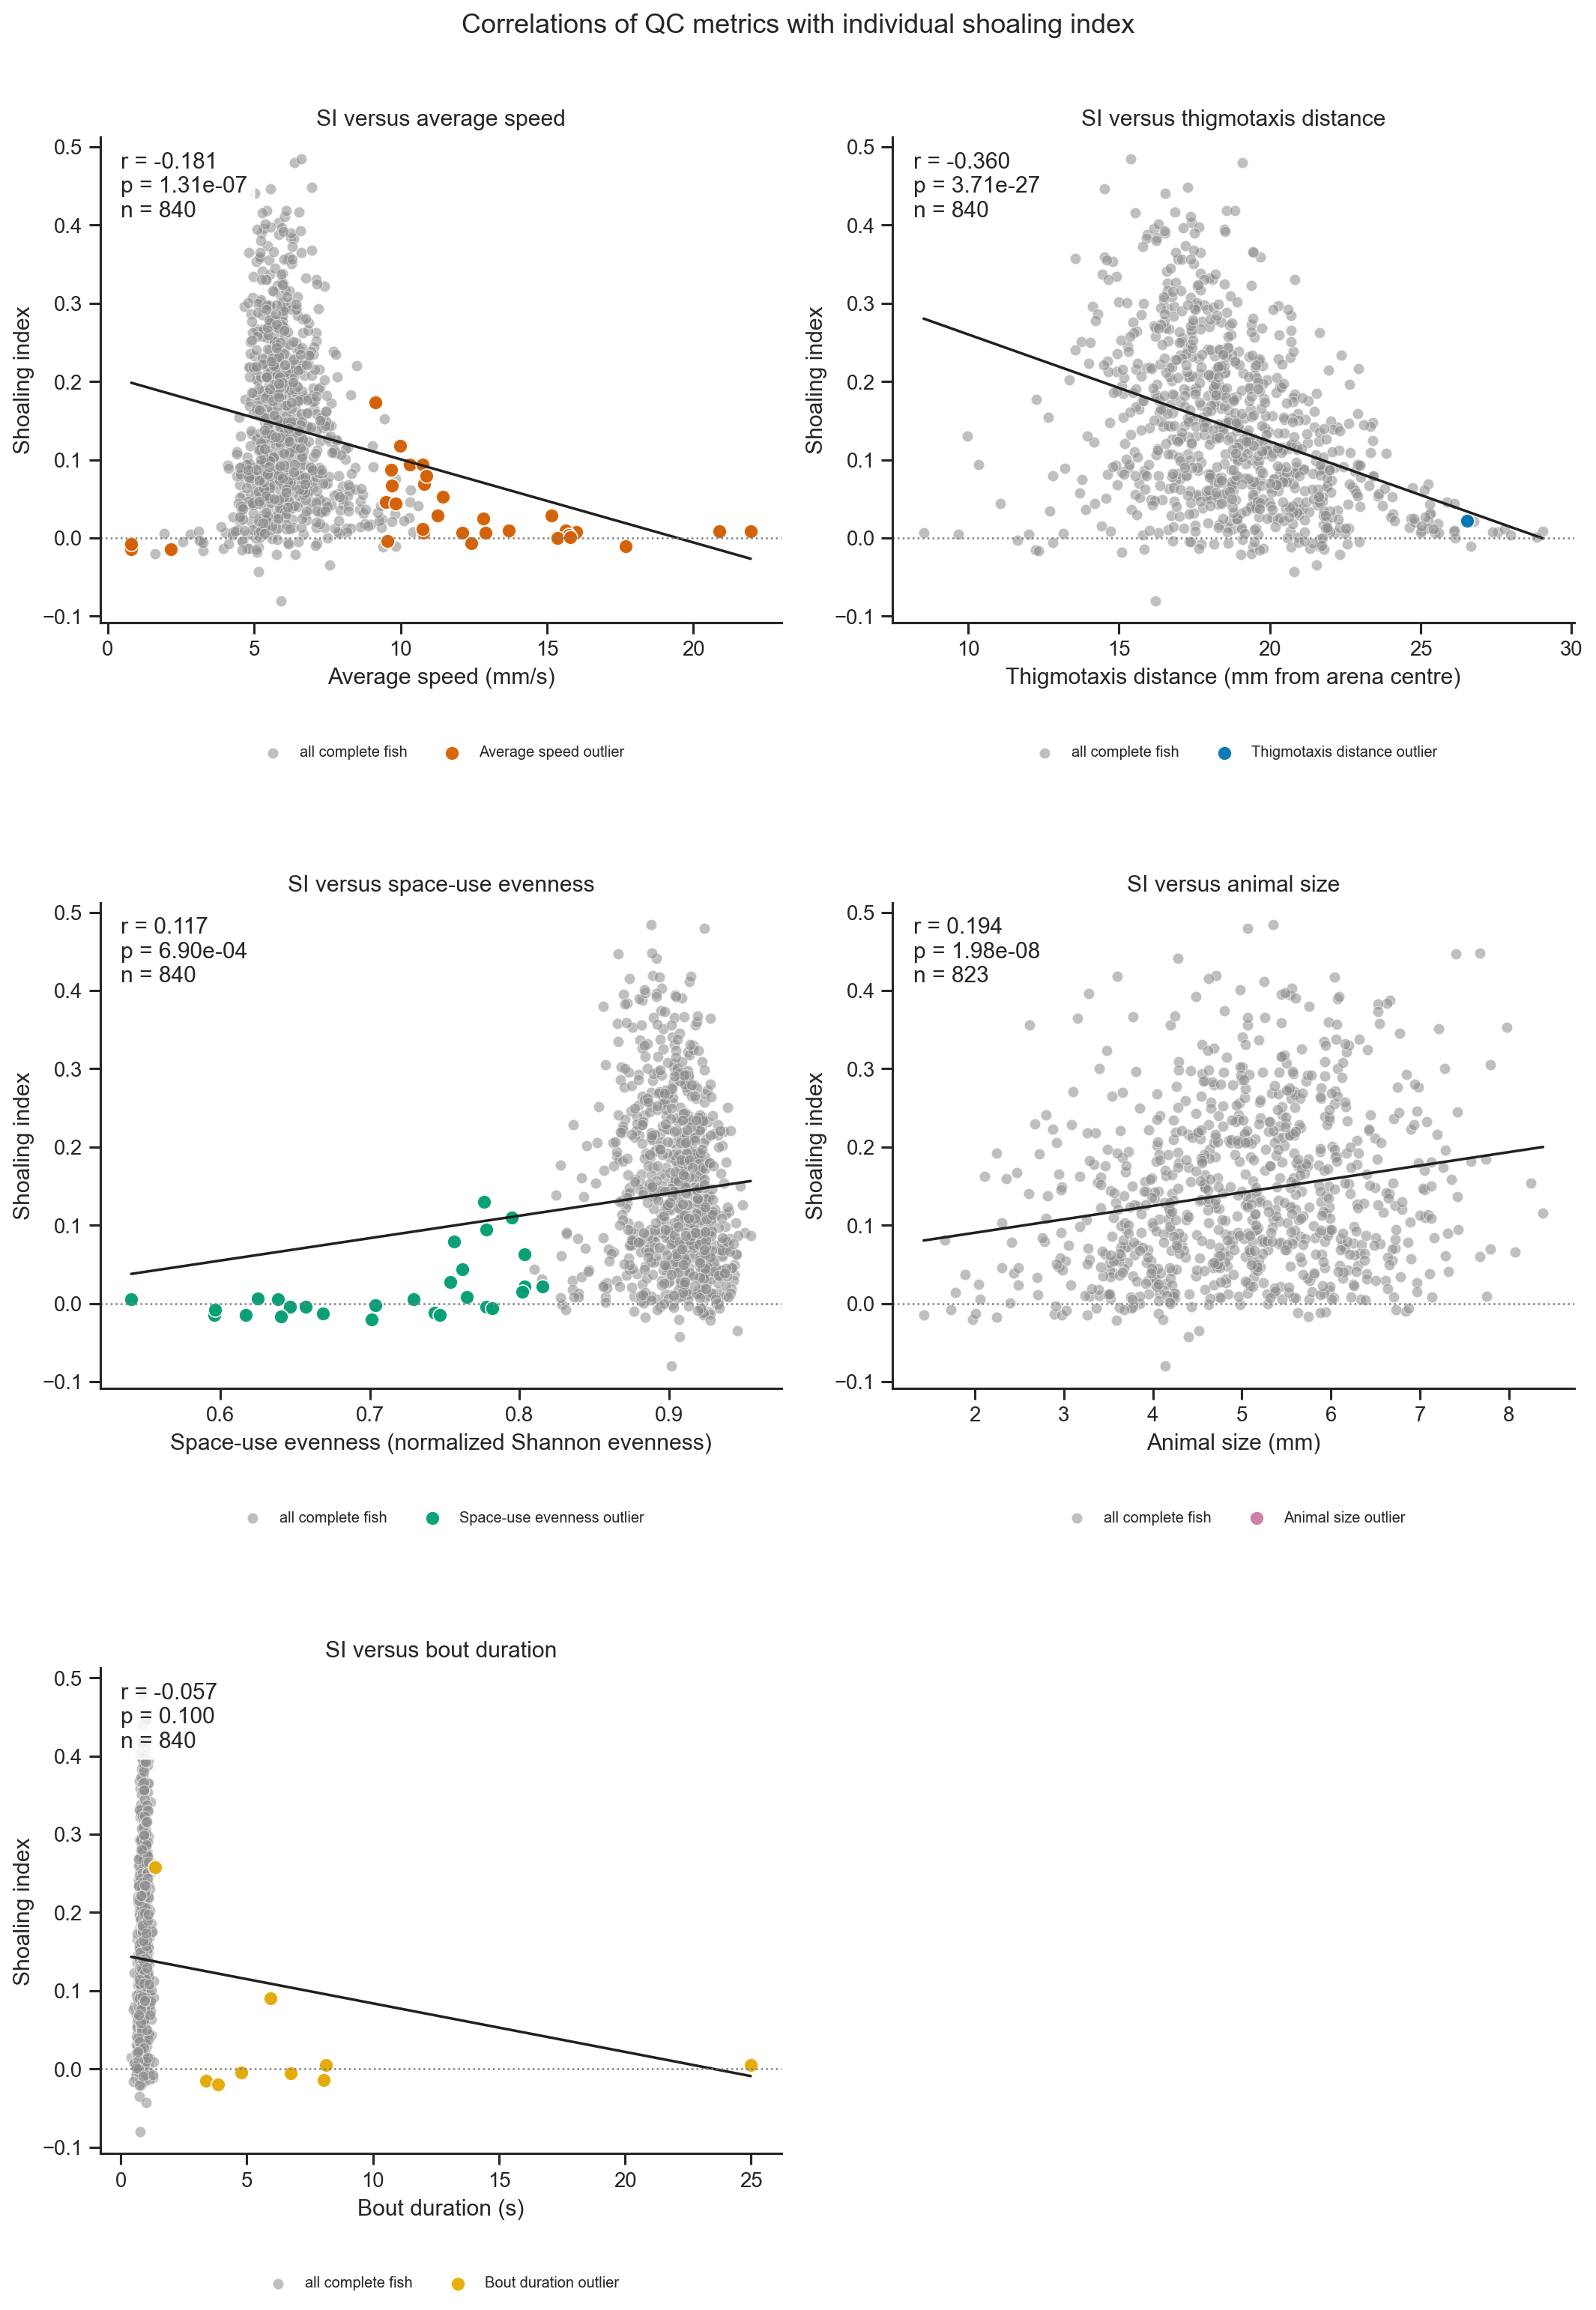

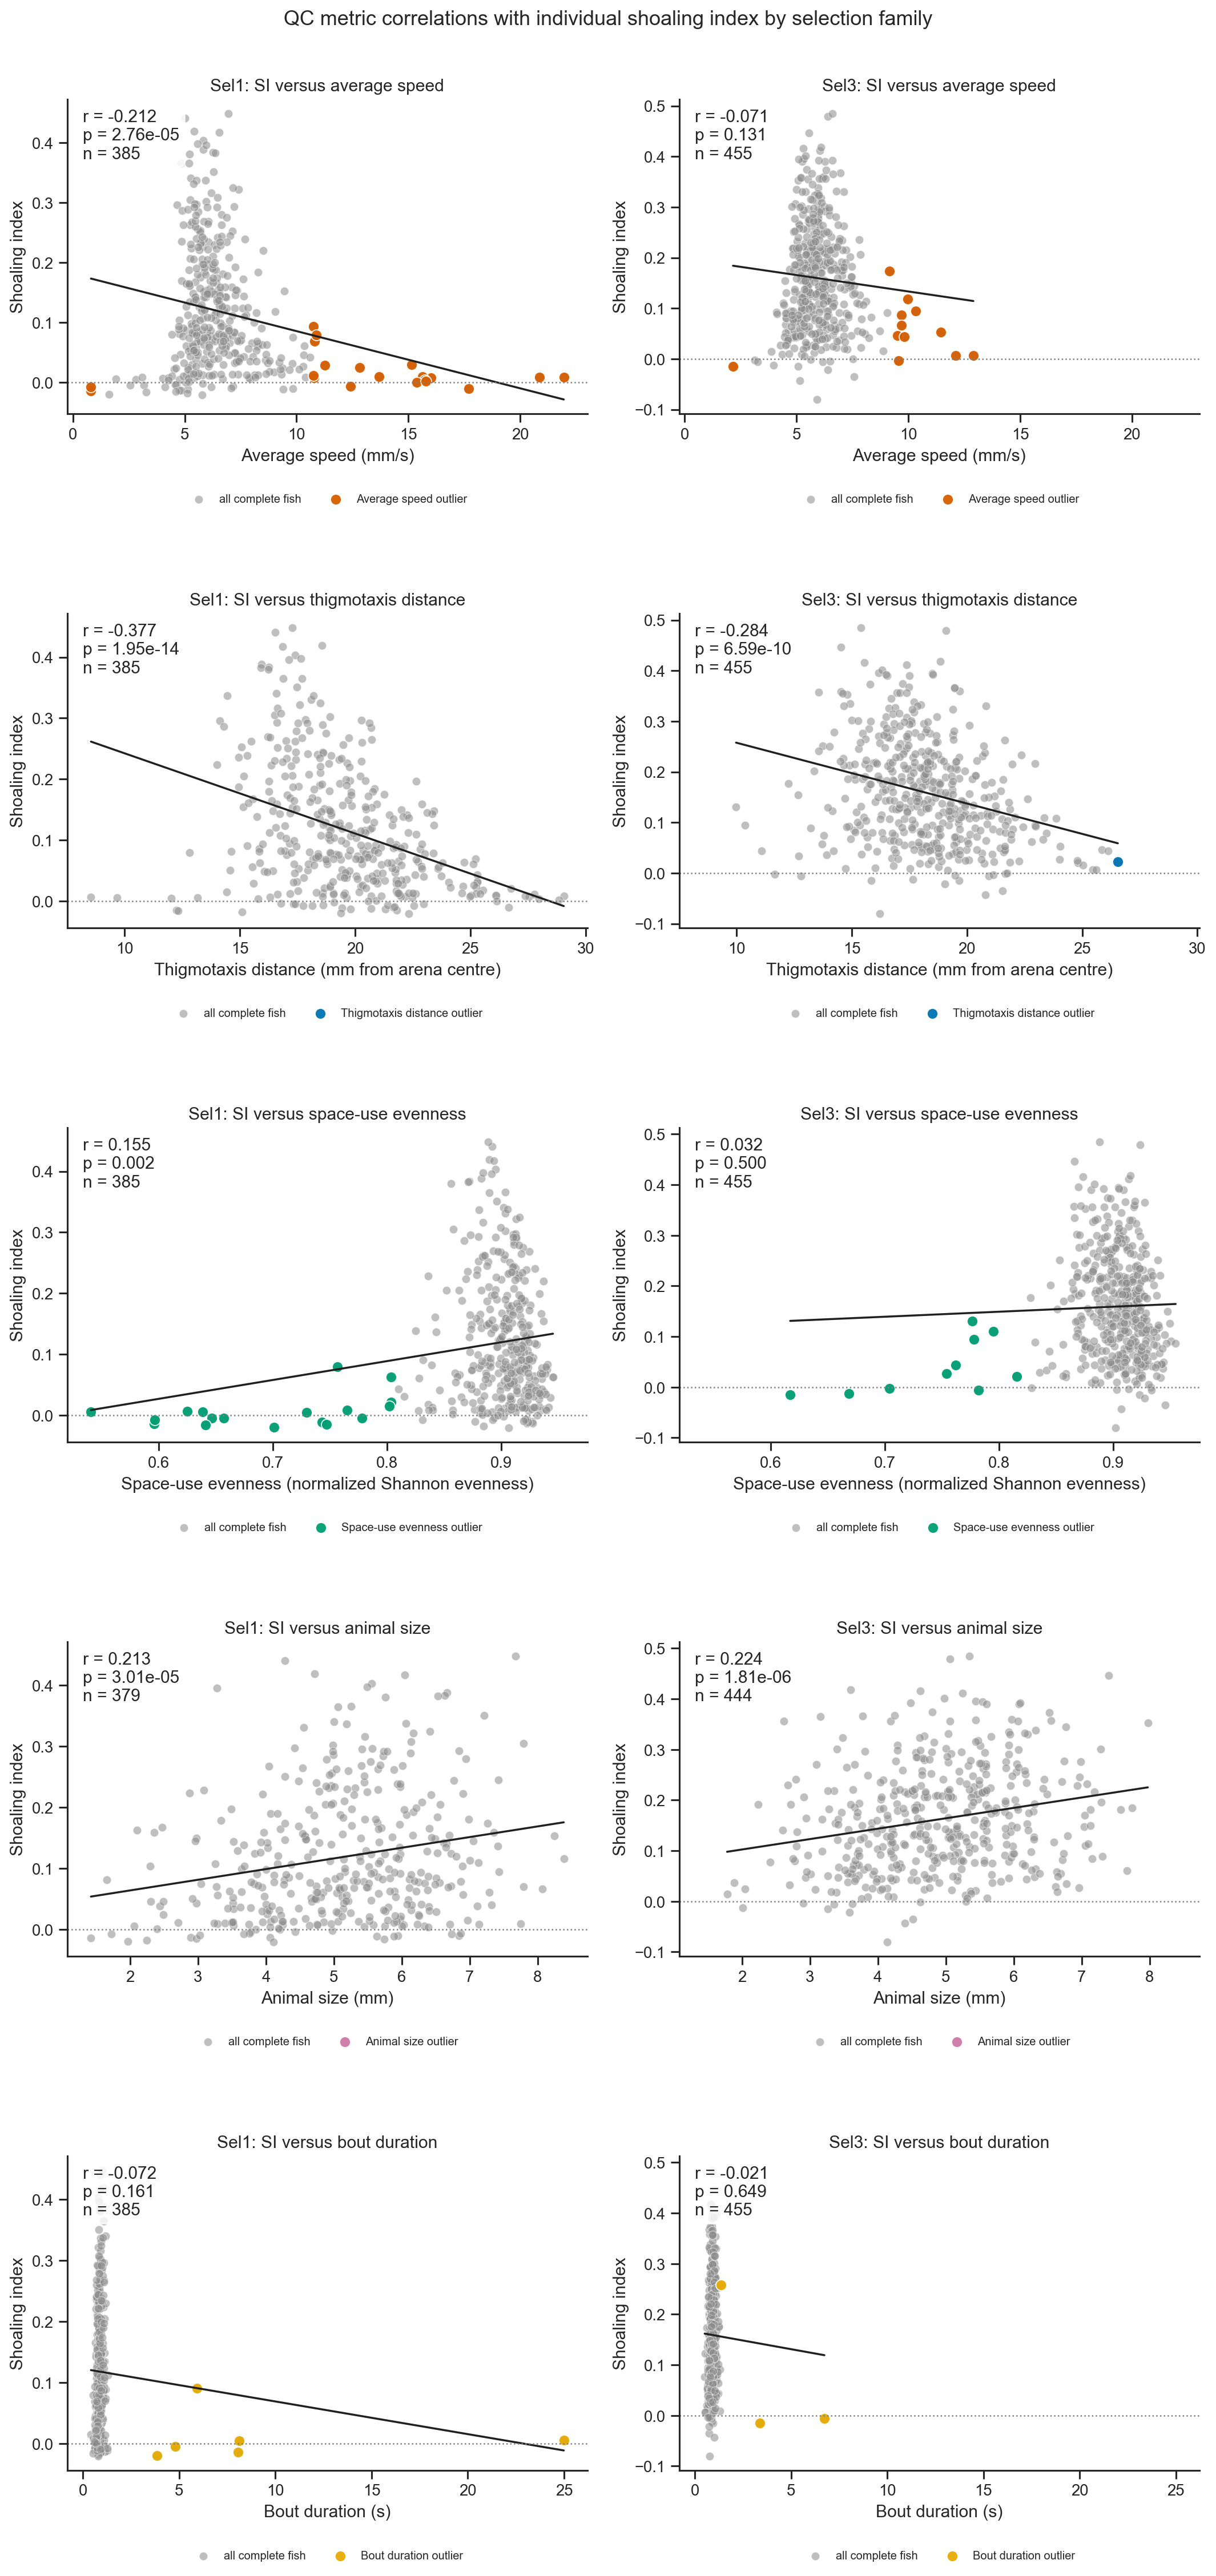

In [12]:
def format_p_value(value):
    """Use compact scientific notation only for small p-values."""
    if not np.isfinite(value):
        return 'N/A'
    return f'{value:.2e}' if value < 0.001 else f'{value:.3f}'


def plot_si_correlation_panel(ax, data, metric_name, title):
    """Plot one complete-case QC metric/SI correlation without excluding flags."""
    metric_info = QC_METRICS[metric_name]
    value_column = metric_info['column']
    outlier_column = f'{metric_name}_outlier_flag'
    complete = data.dropna(subset=[value_column, 'si']).copy()
    metric_outliers = complete[complete[outlier_column]]

    ax.scatter(
        complete[value_column],
        complete['si'],
        s=34,
        color=UNFLAGGED_COLOR,
        alpha=0.55,
        edgecolor='white',
        linewidth=0.4,
        label='all complete fish',
    )
    ax.scatter(
        metric_outliers[value_column],
        metric_outliers['si'],
        s=58,
        color=metric_info['color'],
        alpha=0.95,
        edgecolor='white',
        linewidth=0.7,
        label=f'{metric_info["label"]} outlier',
    )

    if (
        len(complete) >= 3
        and complete[value_column].nunique() > 1
        and complete['si'].nunique() > 1
    ):
        pearson_r, p_value = stats.pearsonr(complete[value_column], complete['si'])
        slope, intercept = np.polyfit(complete[value_column], complete['si'], 1)
        x_line = np.linspace(complete[value_column].min(), complete[value_column].max(), 100)
        ax.plot(x_line, slope * x_line + intercept, color=SUMMARY_COLOR, linewidth=1.4)
    else:
        pearson_r, p_value = np.nan, np.nan

    ax.text(
        0.03,
        0.97,
        f'r = {pearson_r:.3f}\np = {format_p_value(p_value)}\nn = {len(complete)}',
        transform=ax.transAxes,
        ha='left',
        va='top',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.85},
    )
    ax.axhline(0, color='0.5', linestyle=':', linewidth=1)
    ax.set_xlabel(f'{metric_info["label"]} ({metric_info["unit"]})')
    ax.set_ylabel('Shoaling index')
    ax.set_title(title)
    ax.legend(
        frameon=False,
        fontsize=8,
        loc='upper center',
        bbox_to_anchor=(0.5, -0.24),
        ncol=2,
        borderaxespad=0,
    )
    sns.despine(ax=ax)
    return complete, pearson_r, p_value


def plot_si_correlations(data):
    """Plot pooled QC metric/SI correlations without excluding flagged samples."""
    fig, axes = plt.subplots(3, 2, figsize=(12, 17), dpi=FIGURE_DPI)
    axes = axes.ravel()

    for ax, (metric_name, metric_info) in zip(axes, QC_METRICS.items()):
        plot_si_correlation_panel(
            ax, data, metric_name, f'SI versus {metric_info["label"].lower()}'
        )

    for unused_ax in axes[len(QC_METRICS):]:
        unused_ax.remove()

    fig.suptitle('Correlations of QC metrics with individual shoaling index', y=1.01)
    fig.tight_layout(h_pad=4.5)
    return fig, axes


def plot_si_correlations_by_selection_family(data):
    """Plot independent Sel1 and Sel3 correlations for every QC metric."""
    family_data = data.copy()
    family_data['_selection_family'] = family_data['line'].map(
        selection_family_for_threshold
    )
    families = ('Sel1', 'Sel3')
    fig, axes = plt.subplots(
        len(QC_METRICS),
        len(families),
        figsize=(12, 5 * len(QC_METRICS)),
        dpi=FIGURE_DPI,
        sharex='row',
        squeeze=False,
    )

    for row_index, (metric_name, metric_info) in enumerate(QC_METRICS.items()):
        for column_index, family in enumerate(families):
            subset = family_data[family_data['_selection_family'].eq(family)]
            plot_si_correlation_panel(
                axes[row_index, column_index],
                subset,
                metric_name,
                f'{family}: SI versus {metric_info["label"].lower()}',
            )

    fig.suptitle(
        'QC metric correlations with individual shoaling index by selection family',
        y=1.005,
    )
    fig.tight_layout(h_pad=4.5)
    return fig, axes


correlation_figure, _ = plot_si_correlations(qc_table)
save_figure(correlation_figure, 'qtl_qc_si_correlations')

family_correlation_figure, _ = plot_si_correlations_by_selection_family(qc_table)
save_figure(
    family_correlation_figure,
    'qtl_qc_si_correlations_by_selection_family',
)
plt.show()

## 9. Final shoaling-index plot with metric-specific QC overlays

Each sample with non-missing SI has one gray base point and contributes to the experiment mean +/- SD regardless of QC status. Samples with missing SI remain in the tables but cannot be plotted.

Colored hollow markers at the same deterministic jitter position identify metric-specific outliers. Several outlier metrics produce several marker shapes and colors. Missing animal size has a distinct X marker; it does not itself create an outlier flag, although other metrics may flag that sample. Missingness in other QC metrics has no separate marker here.

Counts above each experiment use all its sample rows, including rows with missing SI: unique outliers, each metric's outliers, and missing animal size. They can therefore exceed the number of visible marked points.

Axis ranges are automatic by default. `FINAL_SI_Y_LIMITS` requests an optional manual range, with counts of finite SI points hidden below and above it, including those requiring QC review.


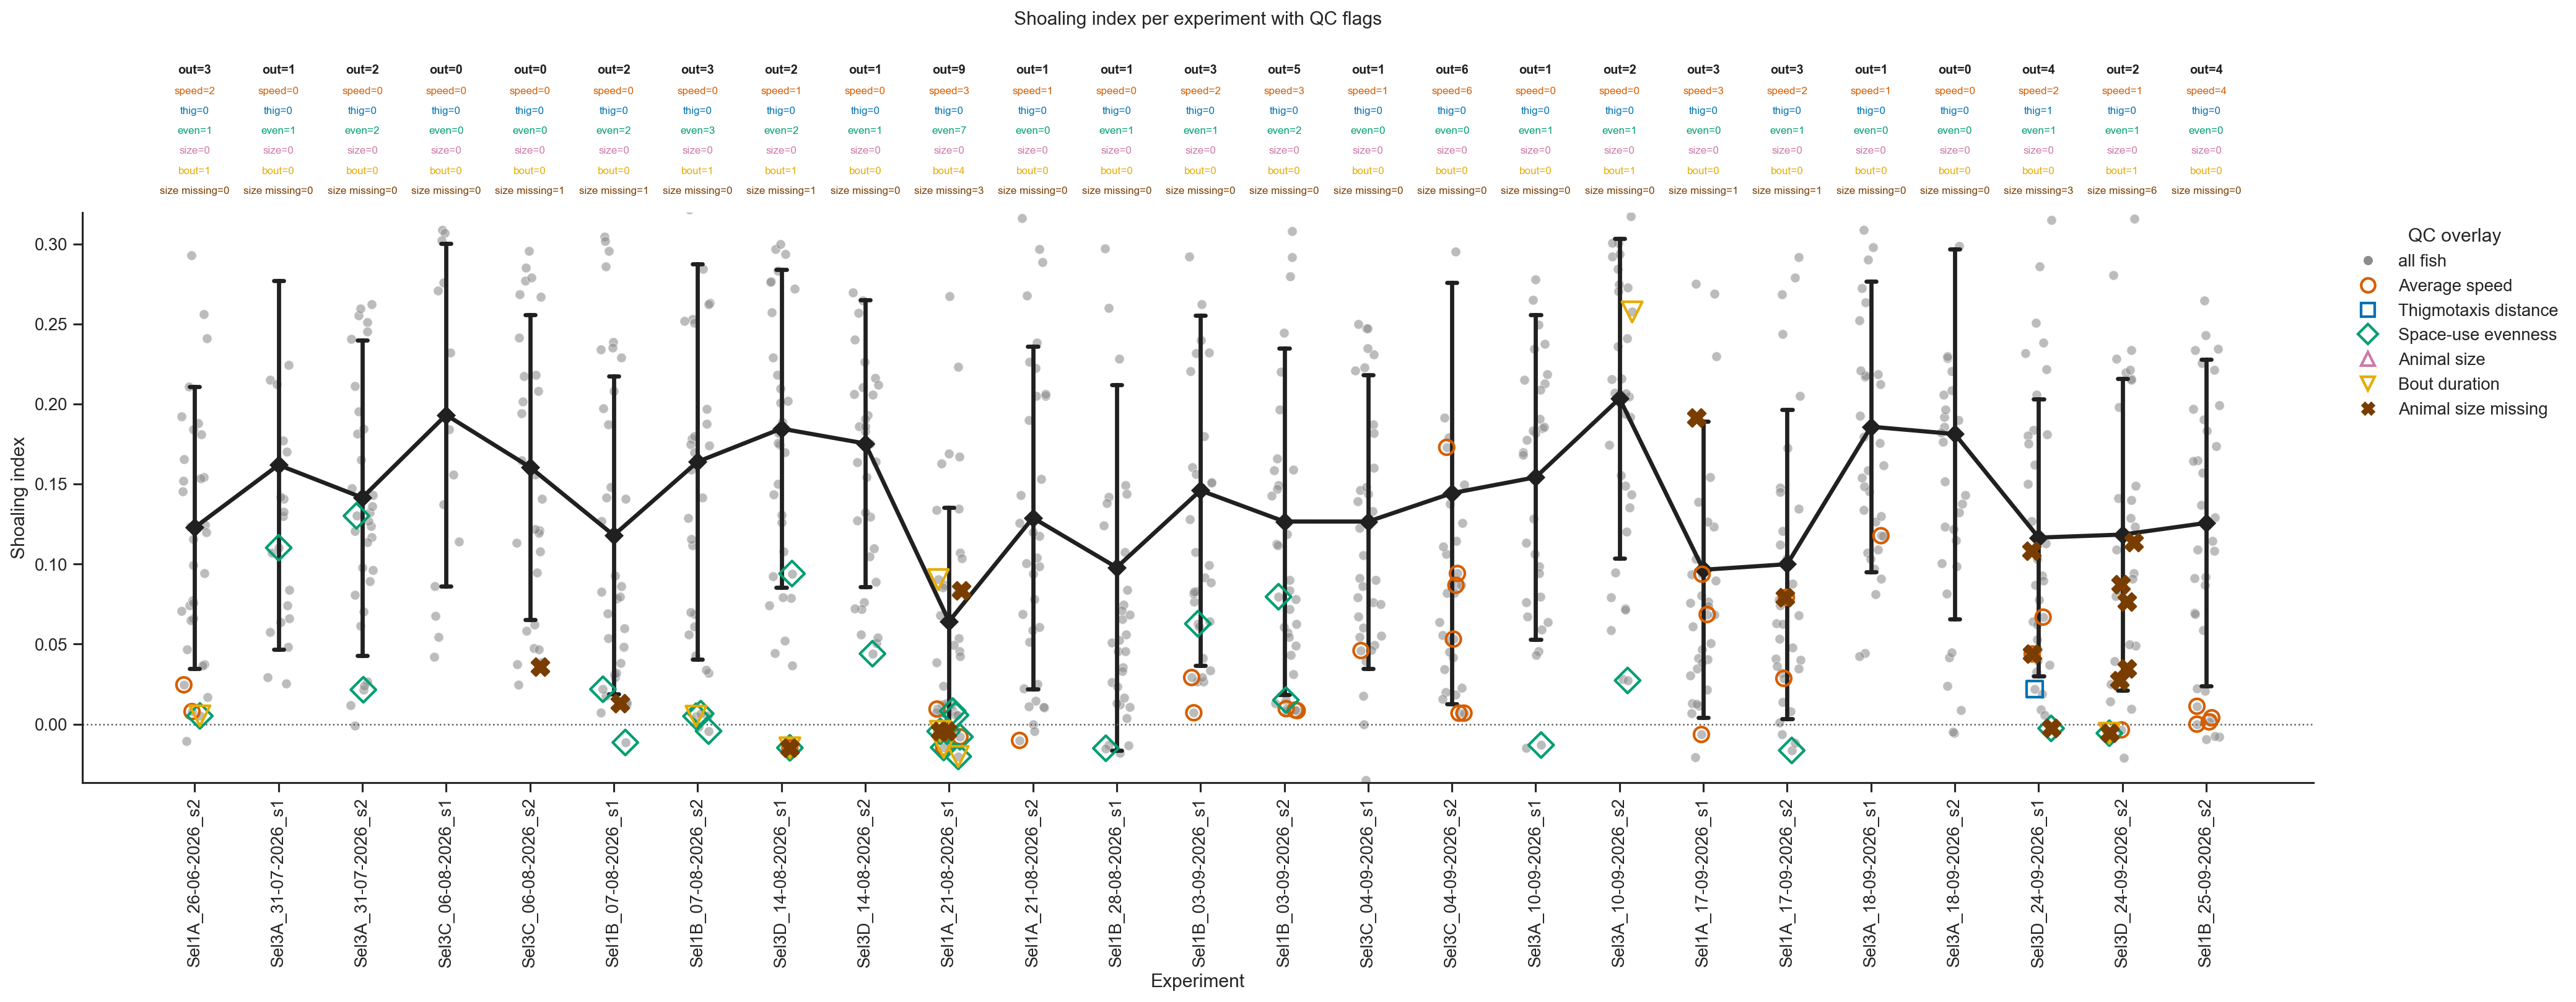

In [13]:
def plot_si_with_qc_outliers(data):
    """Recreate the SI-per-experiment view with multi-metric QC overlays and counts."""
    order = experiment_plot_order(data)
    positioned = add_stable_plot_positions(data, order)
    complete_si = positioned[positioned['si'].notna()].copy()

    fig_width = max(10, 0.85 * len(order) + 2)
    fig, ax = plt.subplots(
        figsize=(fig_width, FINAL_SI_PLOT_HEIGHT),
        dpi=FIGURE_DPI,
    )

    # Each sample with non-missing SI receives one gray base point.
    ax.scatter(
        complete_si['_plot_x'],
        complete_si['si'],
        s=38,
        color=UNFLAGGED_COLOR,
        alpha=0.58,
        edgecolor='white',
        linewidth=0.45,
        zorder=2,
    )

    # Mean and SD include all complete SI values, regardless of QC status.
    sns.pointplot(
        data=complete_si,
        x='experiment_label',
        y='si',
        order=order,
        color=SUMMARY_COLOR,
        errorbar='sd',
        linestyle='-',
        markers='D',
        capsize=0.12,
        ax=ax,
    )

    # Each metric is an independent overlay. Different shapes and sizes keep
    # simultaneous flags visible instead of forcing one arbitrary priority.
    for metric_name, metric_info in QC_METRICS.items():
        marker, marker_size = QC_MARKERS[metric_name]
        metric_outliers = complete_si[complete_si[f'{metric_name}_outlier_flag']]
        ax.scatter(
            metric_outliers['_plot_x'],
            metric_outliers['si'],
            s=marker_size,
            marker=marker,
            facecolors='none',
            edgecolors=metric_info['color'],
            linewidths=1.7,
            zorder=5,
        )

    # Missing animal size requires review but remains distinct from an outlier.
    size_missing = complete_si[complete_si['animal_size_missing_flag']]
    ax.scatter(
        size_missing['_plot_x'],
        size_missing['si'],
        s=132,
        marker='X',
        color='#7A3D00',
        linewidths=1.2,
        zorder=6,
    )

    # Count all experiment-animal rows, including those with missing SI; flags can
    # overlap across metrics, but each row contributes once to the outlier total.
    for x_position, experiment_label in enumerate(order):
        experiment_data = data[data['experiment_label'].eq(experiment_label)]
        unique_total = int(experiment_data['qc_outlier_flag'].sum())
        ax.text(
            x_position,
            1.24,
            f'out={unique_total}',
            transform=ax.get_xaxis_transform(),
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='bold',
            color=SUMMARY_COLOR,
        )
        for count_index, (metric_name, metric_info) in enumerate(QC_METRICS.items()):
            metric_count = int(experiment_data[f'{metric_name}_outlier_flag'].sum())
            ax.text(
                x_position,
                1.205 - 0.035 * count_index,
                f'{metric_info["abbreviation"]}={metric_count}',
                transform=ax.get_xaxis_transform(),
                ha='center',
                va='bottom',
                fontsize=6.8,
                color=metric_info['color'],
            )
        size_missing_count = int(experiment_data['animal_size_missing_flag'].sum())
        ax.text(
            x_position,
            1.205 - 0.035 * len(QC_METRICS),
            f'size missing={size_missing_count}',
            transform=ax.get_xaxis_transform(),
            ha='center',
            va='bottom',
            fontsize=6.8,
            color='#7A3D00',
        )

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker='o',
            linestyle='none',
            markerfacecolor=UNFLAGGED_COLOR,
            markeredgecolor='white',
            label='all fish',
            markersize=7,
        )
    ]
    for metric_name, metric_info in QC_METRICS.items():
        marker, _ = QC_MARKERS[metric_name]
        legend_handles.append(
            Line2D(
                [0],
                [0],
                marker=marker,
                linestyle='none',
                markerfacecolor='none',
                markeredgecolor=metric_info['color'],
                markeredgewidth=1.7,
                label=metric_info['label'],
                markersize=9,
            )
        )
    legend_handles.append(
        Line2D(
            [0],
            [0],
            marker='X',
            linestyle='none',
            markerfacecolor='#7A3D00',
            markeredgecolor='#7A3D00',
            label='Animal size missing',
            markersize=8,
        )
    )

    ax.axhline(0, color='0.35', linestyle=':', linewidth=1)
    ax.set_xlabel('Experiment')
    ax.set_ylabel('Shoaling index')
    if FINAL_SI_Y_LIMITS is not None:
        y_limits = tuple(map(float, FINAL_SI_Y_LIMITS))
        ax.set_ylim(*y_limits)
        below = np.isfinite(complete_si['si']) & complete_si['si'].lt(y_limits[0])
        above = np.isfinite(complete_si['si']) & complete_si['si'].gt(y_limits[1])
        below_review = int((below & complete_si['qc_review_flag']).sum())
        above_review = int((above & complete_si['qc_review_flag']).sum())
        ax.text(
            0.02, 0.98,
            f'Hidden below: {int(below.sum())} points ({below_review} review flagged)\n'
            f'Hidden above: {int(above.sum())} points ({above_review} review flagged)',
            transform=ax.transAxes, ha='left', va='top', fontsize=8,
            bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none'},
        )
    ax.set_title(
        'Shoaling index per experiment with QC flags',
        y=1.33,
        pad=0,
    )
    ax.tick_params(axis='x', rotation=90)
    ax.legend(
        handles=legend_handles,
        title='QC overlay',
        frameon=False,
        bbox_to_anchor=(1.01, 1),
        loc='upper left',
    )
    sns.despine(ax=ax)
    fig.tight_layout()
    return fig, ax


final_si_figure, _ = plot_si_with_qc_outliers(qc_table)
save_figure(final_si_figure, 'qtl_qc_si_by_experiment_with_outliers')
plt.show()

## 10. Outlier counts and animal-size missingness by line

Rows summarize experiment-animal samples by selection line, with an `All lines` total. `Unique flagged fish (outlier or size missing)` counts the union of QC outliers and missing animal size, once per sample. It is narrower than `qc_review_flag`, which also includes missingness in other QC metrics.

Metric outlier counts can overlap; a sample with several outlier metrics contributes once to `Unique outlier fish`. Counts are not deduplicated by `QTLID` across experiments.

In [14]:
outlier_summary_data = qc_table.assign(
    outlier_or_animal_size_missing_flag=(
        qc_table['qc_outlier_flag'] | qc_table['animal_size_missing_flag']
    )
)

outlier_summary_columns = {
    'outlier_or_animal_size_missing_flag': (
        'Unique flagged fish (outlier or size missing)'
    ),
    'qc_outlier_flag': 'Unique outlier fish',
    'animal_size_missing_flag': 'Animal size missing',
    **{
        f'{metric_name}_outlier_flag': metric_info['label']
        for metric_name, metric_info in QC_METRICS.items()
    },
}

outlier_summary_by_line = (
    outlier_summary_data
    .groupby('line', dropna=False)[list(outlier_summary_columns)]
    .sum()
    .astype(int)
    .rename(columns=outlier_summary_columns)
    .sort_index(key=lambda values: values.astype(str).str.casefold())
)
outlier_summary_by_line.loc['All lines'] = (
    outlier_summary_data[list(outlier_summary_columns)]
    .sum()
    .astype(int)
    .rename(index=outlier_summary_columns)
)

display(outlier_summary_by_line)

,Unique flagged fish (outlier or size missing),Unique outlier fish,Animal size missing,Average speed,Thigmotaxis distance,Space-use evenness,Animal size,Bout duration
line,,,,,,,,
Sel1A,22,19,5,11,0,9,0,5
Sel1B,19,18,1,9,0,9,0,1
Sel3A,7,7,0,1,0,5,0,1
Sel3C,8,7,1,7,0,0,0,0
Sel3D,15,9,10,4,1,5,0,2
All lines,71,60,17,32,1,28,0,9
